# Signal-to-image fault diagnosis under a leakage ladder (CWRU + Paderborn)

Companion notebook for the manuscript *"Do Signal-to-Image Transforms Really Generalize? A Leakage-Controlled Benchmark of CNN, Swin and Hybrid Models for Bearing Fault Diagnosis"* (target: MAKE, MDPI).

**What it does**
1. Downloads CWRU (12 kHz drive-end, loads 0–3 hp) and Paderborn/KAt (healthy, artificial and real damage, 4 operating conditions).
2. Builds the evaluation **leakage ladder**:
   * CWRU — L0 random overlapped windows · L1 temporal split inside each recording · L2 leave-one-load-out · L3 fault-size hold-out (unseen fault specimens, 4-class).
   * PU — L0 random overlapped windows · L1 repetition-wise (same bearings) · L3 bearing-wise · X cross-condition (unseen bearings *and* unseen operating condition) · A2R artificial→real damage.
3. **Proposed OASIS-Net** (Order-Aware, Specimen-Invariant Scalogram network): a Swin-T branch on CWT scalograms + a 1-D CNN branch on the speed-normalised envelope order spectrum, gated fusion, and a class-conditional specimen-adversarial head (gradient reversal) that removes recording/bearing identity from the features. Four ablations isolate each component.
4. Baselines: six signal-to-image transforms (STFT, CWT, GASF, GADF, MTF, RP) × image models (ResNet-18, Swin-T, hybrid ResNet+Swin), raw-signal WDCNN and a tuned gradient-boosting model on hand-crafted features.
5. Noise robustness (SNR −4…10 dB, test-time only), computational cost, Friedman/Nemenyi statistics.
6. Exports tables (CSV / Markdown / LaTeX), figures (PNG 300 dpi + PDF) and `paper_numbers.md` with every number the manuscript placeholders need.

**Update (v2):** cells 10b and 10c add OASIS-Net v2. Its configuration (image encoding, image branch, adversary strength, specimen mixing) is chosen in cell 10b by specimen-disjoint inner validation on the TRAINING bearings of PU L3 only; no test bearing or test result is used. Existing results in `results.csv` are kept and skipped, so *Run all* only trains the new runs (about 1 h for 10b and 6–7 h for 10c on a T4; about 2 h in total on an A100).

**How to run:** Runtime → Change runtime type → **A100 GPU** → Run all. Results are appended to `results.csv` on Google Drive after every run, so if Colab disconnects just *Run all* again: finished runs are skipped.

**T4 (free Colab) works too:** the notebook switches to float16 + loss scaling and batch 64 automatically. A T4 is roughly 5–8× slower than an A100 on Swin-T/hybrid, so expect several Colab sessions; just *Run all* again after each disconnect. To shorten it, lower `PU_N_MEAS` to 6 and `EPOCHS` to 10, or set `TOPK = 1`; keep the three seeds.

**Budget (A100, defaults):** downloads + image cache ≈ 30–45 min; stage A (screening, 1 seed) ≈ 1–1.5 h; stage B (top-2 transforms × 3 models × 3 seeds + baselines) ≈ 3–5 h. Reduce `SEEDS`, `PU_N_MEAS` or `EPOCHS` in the config cell to go faster.

**Model selection never looks at test data:** early stopping, GBM tuning and the choice of the top-k transforms all use validation splits drawn from the training side of each protocol.

In [ ]:
# ---------- 0. Environment ----------
import os, sys, subprocess
IN_COLAB = 'google.colab' in sys.modules
SMOKE = os.environ.get('SIG2IMG_SMOKE') == '1'   # internal synthetic-data test; leave unset
if IN_COLAB:
    subprocess.run('pip -q install timm PyWavelets scikit-posthocs', shell=True)
    subprocess.run('apt-get -qq install -y unrar p7zip-full libarchive-tools > /dev/null 2>&1', shell=True)
    from google.colab import drive
    drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# ---------- 1. Configuration ----------
CFG = dict(
    OUT_DIR   = '/content/drive/MyDrive/sig2img_leakage' if IN_COLAB else './sig2img_out',
    DATA_DIR  = '/content/data'  if IN_COLAB else './sig2img_data',
    CACHE_DIR = '/content/cache' if IN_COLAB else './sig2img_cache',
    SEG = 1024,              # samples per window
    OVL_STRIDE = 256,        # stride for the overlapped (L0) pools
    IMG = 64,                # transform output size (IMG x IMG)
    MODEL_IMG = 224,         # input size fed to the image networks (bilinear resize on GPU)
    CWRU_FS = 12000,
    CWRU_NORMAL_FS = 48000,  # CWRU healthy baseline is recorded at 48 kHz -> decimated to 12 kHz
    PU_DECIM = 4,            # PU 64 kHz -> 16 kHz (anti-aliased) so that 1024 samples ~ 1.6 shaft revolutions at 1500 rpm
    PU_N_MEAS = 10,          # measurements per (bearing, condition) used, out of 20
    PU_MAX_SEG = 20,         # non-overlapping windows kept per PU measurement
    PU_MAX_SEG_OVL = 60,     # overlapped windows kept per PU measurement (L0 pool)
    PU_CONDS = ['N15_M07_F10', 'N09_M07_F10', 'N15_M01_F10', 'N15_M07_F04'],
    TRANSFORMS = ['STFT', 'CWT', 'GASF', 'GADF', 'MTF', 'RP'],
    IMAGE_MODELS_FULL = ['resnet18', 'swin', 'hybrid'],
    # OASIS-Net (proposed) and its ablations; hyper-parameters fixed a priori, not tuned on any split
    OASIS_VARIANTS = ['oasis', 'oasis_noadv', 'oasis_noorder', 'oasis_noimg'],
    ORD_MAX = 12.0, ORD_BINS = 128,      # envelope order spectrum: 0.25..12 shaft orders, 128 bins
    ADV_LAMBDA = 0.3, ADV_WEIGHT = 1.0,  # gradient-reversal strength (ramped 0 -> max) and adversary loss weight
    SCREEN_SEEDS = [0],
    SEEDS = [0, 1, 2],
    TOPK = 2,                # transforms promoted from screening (chosen on validation macro-F1)
    EPOCHS = 12, PATIENCE = 4, BATCH = 128, EVAL_BATCH = 256, WD = 0.05,
    LR = {'resnet18': 3e-4, 'swin': 1e-4, 'hybrid': 1e-4, 'wdcnn': 1e-3, 'oasis_backbone': 1e-4, 'oasis_head': 1e-3},
    SNR_DB = [-4, -2, 0, 2, 4, 6, 8, 10],
    NOISE_TESTS = {'CWRU': ('L1', 'test'), 'PU': ('L3X', 'L3')},   # (protocol, test-set) evaluated under noise
    PRETRAINED = True,
    N_WORKERS = os.cpu_count() or 2,
    T4_FAST = True,          # on a T4: TOPK=1, PU_N_MEAS=6, EPOCHS=10 so that the study fits in a few Colab sessions
    PU_LOCAL_DIR = '/content/drive/MyDrive/PU_rar' if IN_COLAB else './PU_rar',   # put the .rar files here if the download is blocked
)
try:
    import torch as _t
    GPU_NAME = _t.cuda.get_device_name(0) if _t.cuda.is_available() else 'cpu'
except Exception:
    GPU_NAME = 'cpu'
if CFG['T4_FAST']:   # the stored results were produced with this preset; keep it on every GPU so all runs are comparable
    CFG.update(TOPK=1, PU_N_MEAS=6, EPOCHS=10)
    print('preset: TOPK=1, PU_N_MEAS=6, EPOCHS=10 (GPU:', GPU_NAME, ')')
# OASIS-Net v2: configuration chosen by specimen-disjoint inner validation on TRAINING bearings only (cell 10b)
CFG['OASIS2_GRID'] = dict(enc=['CWT', 'STFT'], img=['swin', 'hybrid'], lam=[0.0, 0.3, 1.0], mix=[False, True])
CFG['OASIS2_VARIANTS'] = ['oasis2', 'oasis2_noadv', 'oasis2_noorder', 'oasis2_noimg', 'oasis2_nomix']
if SMOKE:
    CFG['OASIS2_GRID'] = dict(enc=['STFT'], img=['hybrid'], lam=[0.3], mix=[True])
if SMOKE:
    CFG.update(SEG=256, OVL_STRIDE=128, IMG=32, MODEL_IMG=224, PU_N_MEAS=5, PU_MAX_SEG=6, PU_MAX_SEG_OVL=8,
               SCREEN_SEEDS=[0], SEEDS=[0], EPOCHS=1, PATIENCE=1, BATCH=16, EVAL_BATCH=16, PRETRAINED=False,
               SNR_DB=[0], N_WORKERS=1, TRANSFORMS=['STFT', 'GASF'], TOPK=1)

import numpy as np, pandas as pd, scipy.io as sio, scipy.signal as ss, json, time, math, random, warnings, urllib.request, glob
from pathlib import Path
from concurrent.futures import ProcessPoolExecutor
warnings.filterwarnings('ignore')
OUT, DATA, CACHE = Path(CFG['OUT_DIR']), Path(CFG['DATA_DIR']), Path(CFG['CACHE_DIR'])
for p in (OUT, OUT / 'tables', OUT / 'figs', DATA / 'CWRU', DATA / 'PU', CACHE):
    p.mkdir(parents=True, exist_ok=True)
SEG = CFG['SEG']
print(json.dumps({k: v for k, v in CFG.items() if k != 'LR'}, indent=1, default=str))

preset: TOPK=1, PU_N_MEAS=6, EPOCHS=10 (GPU: Tesla T4 )
{
 "OUT_DIR": "/content/drive/MyDrive/sig2img_leakage",
 "DATA_DIR": "/content/data",
 "CACHE_DIR": "/content/cache",
 "SEG": 1024,
 "OVL_STRIDE": 256,
 "IMG": 64,
 "MODEL_IMG": 224,
 "CWRU_FS": 12000,
 "CWRU_NORMAL_FS": 48000,
 "PU_DECIM": 4,
 "PU_N_MEAS": 6,
 "PU_MAX_SEG": 20,
 "PU_MAX_SEG_OVL": 60,
 "PU_CONDS": [
  "N15_M07_F10",
  "N09_M07_F10",
  "N15_M01_F10",
  "N15_M07_F04"
 ],
 "TRANSFORMS": [
  "STFT",
  "CWT",
  "GASF",
  "GADF",
  "MTF",
  "RP"
 ],
 "IMAGE_MODELS_FULL": [
  "resnet18",
  "swin",
  "hybrid"
 ],
 "OASIS_VARIANTS": [
  "oasis",
  "oasis_noadv",
  "oasis_noorder",
  "oasis_noimg"
 ],
 "ORD_MAX": 12.0,
 "ORD_BINS": 128,
 "ADV_LAMBDA": 0.3,
 "ADV_WEIGHT": 1.0,
 "SCREEN_SEEDS": [
  0
 ],
 "SEEDS": [
  0,
  1,
  2
 ],
 "TOPK": 1,
 "EPOCHS": 10,
 "PATIENCE": 4,
 "BATCH": 128,
 "EVAL_BATCH": 256,
 "WD": 0.05,
 "SNR_DB": [
  -4,
  -2,
  0,
  2,
  4,
  6,
  8,
  10
 ],
 "NOISE_TESTS": {
  "CWRU": [
   "L1",
   "te

In [ ]:
# ---------- 2. Dataset definitions and download ----------
CWRU_CLASSES = ['N', 'IR007', 'B007', 'OR007', 'IR014', 'B014', 'OR014', 'IR021', 'B021', 'OR021']
# file number at 0 hp; +load gives 1/2/3 hp (CWRU Bearing Data Center tables, OR centred @6:00)
CWRU_BASE = {'N': 97, 'IR007': 105, 'B007': 118, 'OR007': 130, 'IR014': 169, 'B014': 185,
             'OR014': 197, 'IR021': 209, 'B021': 222, 'OR021': 234}
CWRU_URL = 'https://engineering.case.edu/sites/default/files/{}.mat'

# The KAt server refuses connections from Colab; an archived copy of the original .rar files is on Zenodo
# (van den Hoogen, 2025, CC BY 4.0, doi:10.5281/zenodo.15845309). The original server is tried second.
PU_URLS = ['https://zenodo.org/records/15845309/files/{}.rar?download=1',
           'https://groups.uni-paderborn.de/kat/BearingDataCenter/{}.rar']
PU_HEALTHY = ['K001', 'K002', 'K003', 'K004', 'K005', 'K006']
PU_ART  = {'OR': ['KA01', 'KA03', 'KA05', 'KA06', 'KA07', 'KA09'],          # KA08 is not in the Zenodo copy
           'IR': ['KI01', 'KI03', 'KI05', 'KI07', 'KI08']}
PU_REAL = {'OR': ['KA04', 'KA15', 'KA16', 'KA22', 'KA30'],
           'IR': ['KI14', 'KI16', 'KI17', 'KI18', 'KI21']}
# Excluded: KI04 (reported identical to KI14 by Zhao et al., 2020); KB23/KB24/KB27 (combined IR+OR damage);
# KA08 (missing from the archived copy).
PU_ALL = PU_HEALTHY + PU_ART['OR'] + PU_ART['IR'] + PU_REAL['OR'] + PU_REAL['IR']
PU_CLASSES = ['H', 'OR', 'IR']
def pu_class(code):
    return 'H' if code in PU_HEALTHY else ('OR' if code.startswith('KA') else 'IR')
def pu_origin(code):
    return 'healthy' if code in PU_HEALTHY else ('artificial' if code in PU_ART['OR'] + PU_ART['IR'] else 'real')

import socket
_orig_getaddrinfo = socket.getaddrinfo
def _ipv4_first(host, *a, **k):
    """Colab has no IPv6 route; some servers resolve to IPv6 first ('Network is unreachable')."""
    res = _orig_getaddrinfo(host, *a, **k)
    v4 = [r for r in res if r[0] == socket.AF_INET]
    return v4 or res
socket.getaddrinfo = _ipv4_first

def download(url, dst, tries=4):
    dst = Path(dst)
    if dst.exists() and dst.stat().st_size > 0:
        return dst
    local = Path(CFG['PU_LOCAL_DIR']) / dst.name                  # manual copy in Drive, if the server is blocked
    if local.exists() and local.stat().st_size > 0:
        subprocess.run(f'cp "{local}" "{dst}"', shell=True)
        return dst
    if subprocess.run(f'curl -4 -fsSL --retry 3 --connect-timeout 30 -o "{dst}.part" "{url}"', shell=True).returncode == 0:
        os.replace(str(dst) + '.part', dst)
        return dst
    for t in range(tries):
        try:
            req = urllib.request.Request(url, headers={'User-Agent': 'Mozilla/5.0'})
            with urllib.request.urlopen(req, timeout=300) as r, open(str(dst) + '.part', 'wb') as f:
                while True:
                    b = r.read(1 << 20)
                    if not b:
                        break
                    f.write(b)
            os.replace(str(dst) + '.part', dst)
            return dst
        except Exception as e:
            print(f'  retry {t+1}/{tries} {url}: {e}')
            time.sleep(5)
    raise RuntimeError(f'download failed: {url}\n  -> open https://mb.uni-paderborn.de/kat/forschung/bearing-datacenter/data-sets-and-download '
                       f'in a browser, download the .rar files, put them in {CFG["PU_LOCAL_DIR"]} and run this cell again.')

def extract_rar(rar, out):
    rar, out = Path(rar), Path(out)
    if (out / rar.stem).is_dir() and any((out / rar.stem).glob('*.mat')):
        return
    for cmd in (f'unrar x -o+ -inul "{rar}" "{out}/"', f'7z x -y -o"{out}" "{rar}" > /dev/null',
                f'bsdtar -xf "{rar}" -C "{out}"'):
        if subprocess.run(cmd, shell=True).returncode == 0:
            break
    else:
        raise RuntimeError(f'cannot extract {rar}: install unrar or p7zip')
    target = out / rar.stem
    if not (target.is_dir() and any(target.glob('*.mat'))):       # archive with a different folder layout
        target.mkdir(exist_ok=True)
        for f in out.rglob(f'*_{rar.stem}_*.mat'):
            if f.parent != target:
                f.replace(target / f.name)
    if not any(target.glob('*.mat')):
        raise RuntimeError(f'no .mat files for {rar.stem} after extracting {rar}')

if not SMOKE:
    print('CWRU ...')
    for c in CWRU_CLASSES:
        for load in range(4):
            n = CWRU_BASE[c] + load
            download(CWRU_URL.format(n), DATA / 'CWRU' / f'{n}.mat')
    print(f'Paderborn ... ({len(PU_ALL)} archives, about 4.5 GB; first run only)')
    for code in PU_ALL:
        rar = DATA / 'PU' / f'{code}.rar'
        for j, url in enumerate(PU_URLS):
            try:
                download(url.format(code), rar, tries=2)
                break
            except RuntimeError as e:
                if j == len(PU_URLS) - 1:
                    raise e
        extract_rar(rar, DATA / 'PU')
        print('  ok', code)
    print('downloads ok')

CWRU ...
Paderborn ... (27 archives, about 4.5 GB; first run only)
  ok K001
  ok K002
  ok K003
  ok K004
  ok K005
  ok K006
  ok KA01
  ok KA03
  ok KA05
  ok KA06
  ok KA07
  ok KA09
  ok KI01
  ok KI03
  ok KI05
  ok KI07
  ok KI08
  ok KA04
  ok KA15
  ok KA16
  ok KA22
  ok KA30
  ok KI14
  ok KI16
  ok KI17
  ok KI18
  ok KI21
downloads ok


In [ ]:
# ---------- 3. Readers, recordings and window pools ----------
CWRU_NOMINAL_RPM = [1797, 1772, 1750, 1730]          # 0..3 hp, used only if a file has no RPM field
def read_cwru(num, load):
    m = sio.loadmat(DATA / 'CWRU' / f'{num}.mat')
    keys = [k for k in m if k.endswith('_DE_time')]
    pref = [k for k in keys if k.startswith(f'X{num:03d}')]
    x = np.asarray(m[(pref or keys)[0]], dtype=np.float64).ravel()
    rk = [k for k in m if k.endswith('RPM')]
    rpm = float(np.ravel(m[rk[0]])[0]) if rk else float(CWRU_NOMINAL_RPM[load])
    return x, rpm

def read_pu(path):
    m = sio.loadmat(path, squeeze_me=True, struct_as_record=False)
    key = [k for k in m if not k.startswith('__')][0]
    for ch in np.atleast_1d(m[key].Y):
        if str(ch.Name).strip() == 'vibration_1':
            return np.asarray(ch.Data, dtype=np.float64).ravel()
    raise KeyError(f'vibration_1 not in {path}')

def make_synthetic_data():
    """SMOKE only: synthetic stand-ins with the real file layouts (never used for results)."""
    rng = np.random.default_rng(0)
    def sig(n, f, fs):
        t = np.arange(n) / fs
        return np.sin(2 * np.pi * f * t) + 0.5 * rng.standard_normal(n)
    for i, c in enumerate(CWRU_CLASSES):
        for load in range(4):
            n = CWRU_BASE[c] + load
            fs = CFG['CWRU_NORMAL_FS'] if c == 'N' else CFG['CWRU_FS']
            sio.savemat(DATA / 'CWRU' / f'{n}.mat', {f'X{n:03d}_DE_time': sig(fs // 2, 100 + 37 * i, fs)[:, None]})
    for j, code in enumerate(PU_ALL):
        d = DATA / 'PU' / code
        d.mkdir(exist_ok=True)
        for cond in CFG['PU_CONDS']:
            for k in range(1, CFG['PU_N_MEAS'] + 1):
                name = f'{cond}_{code}_{k}'
                f0 = {'H': 50, 'OR': 90, 'IR': 160}[pu_class(code)]
                Y = np.zeros(2, dtype=[('Name', 'O'), ('Data', 'O')])
                Y[0] = ('force', rng.standard_normal(100)); Y[1] = ('vibration_1', sig(64000 // 4, f0, 64000))
                sio.savemat(d / f'{name}.mat', {name: {'Y': Y}})

if SMOKE:
    make_synthetic_data()

def load_recordings():
    recs = []
    for c in CWRU_CLASSES:
        for load in range(4):
            x, rpm = read_cwru(CWRU_BASE[c] + load, load)
            if c == 'N':                                   # 48 kHz -> 12 kHz
                x = ss.decimate(x, CFG['CWRU_NORMAL_FS'] // CFG['CWRU_FS'], ftype='fir', zero_phase=True)
            ctype = 'N' if c == 'N' else c.rstrip('0123456789')
            size = None if c == 'N' else c[len(ctype):]
            recs.append(dict(dataset='CWRU', rec=f'CWRU_{c}_{load}', cls=c, ctype=ctype, size=size,
                             cond=f'{load}hp', bearing=c if c != 'N' else 'N', meas=0, rpm=rpm, fs=CFG['CWRU_FS'],
                             x=x.astype(np.float32)))
    for code in PU_ALL:
        for cond in CFG['PU_CONDS']:
            for k in range(1, CFG['PU_N_MEAS'] + 1):
                p = DATA / 'PU' / code / f'{cond}_{code}_{k}.mat'
                try:
                    x = read_pu(p)
                except Exception as e:
                    print('  skip', p.name, e); continue
                x = ss.decimate(x, CFG['PU_DECIM'], ftype='fir', zero_phase=True)
                recs.append(dict(dataset='PU', rec=f'PU_{code}_{cond}_{k}', cls=pu_class(code), ctype=pu_class(code),
                                 size=None, cond=cond, bearing=code, meas=k, origin=pu_origin(code),
                                 rpm=1500.0 if cond.startswith('N15') else 900.0, fs=64000 // CFG['PU_DECIM'],
                                 x=x.astype(np.float32)))
    return recs

def build_pool(recs, stride, max_seg=None, seed=0):
    rng = np.random.default_rng(seed)
    X, rows = [], []
    for r in recs:
        st = np.arange(0, len(r['x']) - SEG + 1, stride)
        if max_seg and len(st) > max_seg:
            st = np.sort(rng.choice(st, max_seg, replace=False))
        for s in st:
            X.append(r['x'][s:s + SEG])
            rows.append({k: v for k, v in r.items() if k != 'x'} | {'start': int(s), 'rec_len': len(r['x'])})
    return np.stack(X).astype(np.float32), pd.DataFrame(rows)

t0 = time.time()
RECS = load_recordings()
cw = [r for r in RECS if r['dataset'] == 'CWRU']
pu = [r for r in RECS if r['dataset'] == 'PU']
pu0_hr = [r for r in pu if r['cond'] == CFG['PU_CONDS'][0] and r['origin'] in ('healthy', 'real')]
POOLS = {
    'cwru_ovl': build_pool(cw, CFG['OVL_STRIDE']),
    'cwru_non': build_pool(cw, SEG),
    'pu_ovl':   build_pool(pu0_hr, CFG['OVL_STRIDE'], CFG['PU_MAX_SEG_OVL']),
    'pu_non':   build_pool(pu, SEG, CFG['PU_MAX_SEG']),
}
del RECS
for k, (X, M) in POOLS.items():
    print(f'{k:9s} windows={len(X):6d}  recordings={M.rec.nunique():4d}  classes={sorted(M.cls.unique())}')
print(f'pools built in {time.time()-t0:.0f}s')

cwru_ovl  windows= 18671  recordings=  40  classes=['B007', 'B014', 'B021', 'IR007', 'IR014', 'IR021', 'N', 'OR007', 'OR014', 'OR021']
cwru_non  windows=  4683  recordings=  40  classes=['B007', 'B014', 'B021', 'IR007', 'IR014', 'IR021', 'N', 'OR007', 'OR014', 'OR021']
pu_ovl    windows=  5760  recordings=  96  classes=['H', 'IR', 'OR']
pu_non    windows= 12960  recordings= 648  classes=['H', 'IR', 'OR']
pools built in 10s


In [ ]:
# ---------- 4. Protocols (the leakage ladder) ----------
from sklearn.model_selection import train_test_split

def _random_split(M, seed, strat_cols):
    idx = np.arange(len(M))
    strat = M[strat_cols].astype(str).agg('|'.join, axis=1).values
    tr, te = train_test_split(idx, test_size=0.3, random_state=seed, stratify=strat)
    tr, va = train_test_split(tr, test_size=1 / 7, random_state=seed, stratify=strat[tr])
    return tr, va, te

def _temporal(M, lo, hi):
    """windows lying entirely inside [lo, hi) fraction of their recording"""
    a, b = M.start.values / M.rec_len.values, (M.start.values + SEG) / M.rec_len.values
    return (a >= lo - 1e-9) & (b <= hi + 1e-9)

def build_folds(seed):
    F = []
    # ---------------- CWRU (10-class for L0-L2, 4-class for L3) ----------------
    _, M = POOLS['cwru_ovl']
    tr, va, te = _random_split(M, seed, ['cls', 'cond'])
    F.append(dict(key=f'CWRU|L0|s{seed}', dataset='CWRU', protocol='L0', pool='cwru_ovl', ycol='cls',
                  classes=CWRU_CLASSES, train=tr, val=va, tests={'test': te}))
    _, M = POOLS['cwru_non']
    F.append(dict(key=f'CWRU|L1|s{seed}', dataset='CWRU', protocol='L1', pool='cwru_non', ycol='cls',
                  classes=CWRU_CLASSES, train=np.where(_temporal(M, 0, .6))[0],
                  val=np.where(_temporal(M, .6, .7))[0], tests={'test': np.where(_temporal(M, .7, 1))[0]}))
    for L in range(4):
        src, tgt = (M.cond != f'{L}hp').values, (M.cond == f'{L}hp').values
        F.append(dict(key=f'CWRU|L2|load{L}|s{seed}', dataset='CWRU', protocol='L2', pool='cwru_non', ycol='cls',
                      classes=CWRU_CLASSES, train=np.where(src & _temporal(M, 0, .85))[0],
                      val=np.where(src & _temporal(M, .85, 1))[0], tests={f'load{L}': np.where(tgt)[0]}))
    for s in ['007', '014', '021']:
        fault, normal = (M.ctype != 'N').values, (M.ctype == 'N').values
        held = (M['size'] == s).values
        tr = (fault & ~held & _temporal(M, 0, .85)) | (normal & _temporal(M, 0, .6))
        va = (fault & ~held & _temporal(M, .85, 1)) | (normal & _temporal(M, .6, .7))
        te = (fault & held) | (normal & _temporal(M, .7, 1))
        F.append(dict(key=f'CWRU|L3|size{s}|s{seed}', dataset='CWRU', protocol='L3', pool='cwru_non', ycol='ctype',
                      classes=['N', 'IR', 'B', 'OR'], train=np.where(tr)[0], val=np.where(va)[0],
                      tests={f'size{s}': np.where(te)[0]}))
    # ---------------- Paderborn (3-class H / OR / IR) ----------------
    _, M = POOLS['pu_ovl']
    tr, va, te = _random_split(M, seed, ['bearing'])
    F.append(dict(key=f'PU|L0|s{seed}', dataset='PU', protocol='L0', pool='pu_ovl', ycol='cls',
                  classes=PU_CLASSES, train=tr, val=va, tests={'test': te}))
    _, M = POOLS['pu_non']
    nm = CFG['PU_N_MEAS']
    c0 = (M.cond == CFG['PU_CONDS'][0]).values
    hr = M.origin.isin(['healthy', 'real']).values
    F.append(dict(key=f'PU|L1|s{seed}', dataset='PU', protocol='L1', pool='pu_non', ycol='cls', classes=PU_CLASSES,
                  train=np.where(c0 & hr & (M.meas <= round(.6 * nm)).values)[0],
                  val=np.where(c0 & hr & (M.meas == round(.6 * nm) + 1).values)[0],
                  tests={'test': np.where(c0 & hr & (M.meas > round(.7 * nm)).values)[0]}))
    rng = np.random.default_rng(1000 + seed)
    h = list(rng.permutation(PU_HEALTHY)); o = list(rng.permutation(PU_REAL['OR'])); i = list(rng.permutation(PU_REAL['IR']))
    train_b, test_b = h[:4] + o[:3] + i[:3], h[4:] + o[3:] + i[3:]
    inb_tr, inb_te = M.bearing.isin(train_b).values, M.bearing.isin(test_b).values
    early, late = (M.meas <= round(.8 * nm)).values, (M.meas > round(.8 * nm)).values
    tests = {'L3': np.where(c0 & inb_te)[0]}
    for cond in CFG['PU_CONDS'][1:]:
        tests[f'X-{cond}'] = np.where((M.cond == cond).values & inb_te)[0]
    F.append(dict(key=f'PU|L3X|s{seed}', dataset='PU', protocol='L3X', pool='pu_non', ycol='cls', classes=PU_CLASSES,
                  train=np.where(c0 & inb_tr & early)[0], val=np.where(c0 & inb_tr & late)[0], tests=tests,
                  info={'train_bearings': train_b, 'test_bearings': test_b}))
    hh = list(rng.permutation(PU_HEALTHY))
    art = M.origin.eq('artificial').values
    src = c0 & (M.bearing.isin(hh[:3]).values | art)
    tgt = c0 & (M.bearing.isin(hh[3:]).values | M.origin.eq('real').values)
    F.append(dict(key=f'PU|A2R|s{seed}', dataset='PU', protocol='A2R', pool='pu_non', ycol='cls', classes=PU_CLASSES,
                  train=np.where(src & early)[0], val=np.where(src & late)[0], tests={'A2R': np.where(tgt)[0]},
                  info={'train_healthy': hh[:3], 'test_healthy': hh[3:]}))
    return F

def audit_fold(f):
    """Leakage audit: share of test windows that overlap in time with a training window of the same recording,
    and share of test windows whose physical bearing also appears in training."""
    _, M = POOLS[f['pool']]
    tr, out = M.iloc[f['train']], {}
    spans = {}
    for rec, st in zip(tr.rec.values, tr.start.values):
        spans.setdefault(rec, []).append(st)
    spans = {k: np.sort(v) for k, v in spans.items()}
    trb = set(tr.bearing.values)
    for name, idx in f['tests'].items():
        te = M.iloc[idx]
        ov = 0
        for rec, st in zip(te.rec.values, te.start.values):
            s = spans.get(rec)
            if s is not None:
                j = np.searchsorted(s, st)
                if (j < len(s) and s[j] - st < SEG) or (j > 0 and st - s[j - 1] < SEG):
                    ov += 1
        out[name] = dict(overlap_frac=ov / max(len(te), 1),
                         same_recording_frac=float(te.rec.isin(spans.keys()).mean()),
                         same_bearing_frac=float(te.bearing.isin(trb).mean()), n_test=len(te))
    return out

AUDIT = []
for f in build_folds(0):
    for name, a in audit_fold(f).items():
        AUDIT.append(dict(fold=f['key'].rsplit('|', 1)[0], test=name, n_train=len(f['train']), n_val=len(f['val']), **a))
AUDIT = pd.DataFrame(AUDIT)
AUDIT.to_csv(OUT / 'tables' / 'leakage_audit.csv', index=False)
print(AUDIT.to_string(index=False))

           fold          test  n_train  n_val  overlap_frac  same_recording_frac  same_bearing_frac  n_test
        CWRU|L0          test    11202   1867      0.996608             1.000000           1.000000    5602
        CWRU|L1          test     2804    429      0.000000             1.000000           1.000000    1370
  CWRU|L2|load0         load0     3023    504      0.000000             0.000000           1.000000    1126
  CWRU|L2|load1         load1     2974    494      0.000000             0.000000           1.000000    1185
  CWRU|L2|load2         load2     2974    495      0.000000             0.000000           1.000000    1184
  CWRU|L2|load3         load3     2972    493      0.000000             0.000000           1.000000    1188
CWRU|L3|size007       size007     2670    435      0.000000             0.078913           0.078913    1546
CWRU|L3|size014       size014     2666    442      0.000000             0.079067           0.079067    1543
CWRU|L3|size021       size02

In [ ]:
# ---------- 5. Signal-to-image transforms ----------
import pywt
IMG = CFG['IMG']

def _z(X):
    X = X.astype(np.float64)
    return (X - X.mean(1, keepdims=True)) / (X.std(1, keepdims=True) + 1e-12)

def _paa(X, n):
    return X.reshape(len(X), n, -1).mean(-1)

def _minmax_img(I):
    lo = I.reshape(len(I), -1).min(1)[:, None, None]
    hi = I.reshape(len(I), -1).max(1)[:, None, None]
    return ((I - lo) / (hi - lo + 1e-12)).astype(np.float16)

def _resize_time(A, n):           # (..., T) -> (..., n): mean over n contiguous (near-equal) bins
    T = A.shape[-1]
    if T < n:
        return A[..., np.linspace(0, T - 1, n).round().astype(int)]
    edges = np.linspace(0, T, n + 1).astype(int)
    return np.add.reduceat(A, edges[:-1], axis=-1) / np.diff(edges)

def t_stft(X):
    Z = _z(X)
    nper = 2 * IMG - 2                                   # -> IMG frequency bins
    hop = max(1, (SEG - nper) // (IMG - 1))             # -> about IMG frames
    _, _, S = ss.stft(Z, nperseg=nper, noverlap=nper - hop, boundary=None, padded=False, axis=-1)
    S = np.log1p(np.abs(S))                              # (B, IMG, frames)
    return _minmax_img(_resize_time(S, IMG)[:, ::-1, :].copy())

CWT_SCALES = np.geomspace(2, 128, IMG)
def t_cwt(X):
    C, _ = pywt.cwt(_z(X), CWT_SCALES, 'morl', method='fft', axis=-1)   # (IMG, B, SEG)
    C = np.log1p(np.abs(np.moveaxis(C, 0, 1)))
    return _minmax_img(_resize_time(C, IMG))

def _gaf_parts(X):
    P = _paa(_z(X), IMG)
    lo, hi = P.min(1, keepdims=True), P.max(1, keepdims=True)
    c = np.clip(2 * (P - lo) / (hi - lo + 1e-12) - 1, -1, 1)
    s = np.sqrt(np.clip(1 - c ** 2, 0, 1))
    return c, s

def t_gasf(X):
    c, s = _gaf_parts(X)
    return _minmax_img(c[:, :, None] * c[:, None, :] - s[:, :, None] * s[:, None, :])

def t_gadf(X):
    c, s = _gaf_parts(X)
    return _minmax_img(s[:, :, None] * c[:, None, :] - c[:, :, None] * s[:, None, :])

MTF_Q = 8
def t_mtf(X):
    Z = _z(X)
    out = np.empty((len(Z), IMG, IMG))
    for k, z in enumerate(Z):
        q = np.searchsorted(np.quantile(z, np.linspace(0, 1, MTF_Q + 1)[1:-1]), z)      # bin index 0..Q-1
        W = np.zeros((MTF_Q, MTF_Q)); np.add.at(W, (q[:-1], q[1:]), 1)
        W /= W.sum(1, keepdims=True) + 1e-12
        H = np.eye(MTF_Q)[q].reshape(IMG, -1, MTF_Q).mean(1)                            # block histograms (IMG, Q)
        out[k] = H @ W @ H.T                                                            # = block-averaged full MTF
    return _minmax_img(out)

def t_rp(X):
    P = _paa(_z(X), IMG)
    return _minmax_img(np.abs(P[:, :, None] - P[:, None, :]))   # unthresholded recurrence plot (m = 1)

TRANSFORM_FN = {'STFT': t_stft, 'CWT': t_cwt, 'GASF': t_gasf, 'GADF': t_gadf, 'MTF': t_mtf, 'RP': t_rp}

def _apply(args):
    name, X = args
    return TRANSFORM_FN[name](X)

def transform(name, X, chunk=512):
    chunks = [(name, X[i:i + chunk]) for i in range(0, len(X), chunk)]
    if CFG['N_WORKERS'] > 1 and len(chunks) > 1:
        with ProcessPoolExecutor(CFG['N_WORKERS']) as ex:
            return np.concatenate(list(ex.map(_apply, chunks)))
    return np.concatenate([_apply(c) for c in chunks])

IMG_CACHE = {}
def get_images(pool, name):
    key = (pool, name)
    if key not in IMG_CACHE:
        f = CACHE / f'{pool}_{name}_{SEG}_{IMG}.npy'
        if f.exists():
            IMG_CACHE[key] = np.load(f)
        else:
            t = time.time()
            IMG_CACHE[key] = transform(name, POOLS[pool][0])
            np.save(f, IMG_CACHE[key])
            print(f'  {pool:9s} {name:5s} {len(IMG_CACHE[key])} images in {time.time()-t:.0f}s')
    return IMG_CACHE[key]

# transform cost (single CPU core, ms per window) for the cost table
COST = []
Xb = POOLS['cwru_non'][0][:256]
for n in dict.fromkeys(CFG['TRANSFORMS'] + ['CWT']):     # CWT is always timed: OASIS-Net uses it
    TRANSFORM_FN[n](Xb[:8]); t = time.perf_counter(); TRANSFORM_FN[n](Xb); dt = time.perf_counter() - t
    COST.append(dict(transform=n, ms_per_window=1000 * dt / len(Xb)))
COST = pd.DataFrame(COST); COST.to_csv(OUT / 'tables' / 'transform_cost.csv', index=False)
print(COST.to_string(index=False))

transform  ms_per_window
     STFT       0.219654
      CWT       2.324777
     GASF       0.073013
     GADF       0.066683
      MTF       0.534422
       RP       0.055759


In [ ]:
# ---------- 6. Hand-crafted features (GBM baseline) and noise ----------
def features(X):
    Z = X.astype(np.float64)
    a = np.abs(Z); rms = np.sqrt((Z ** 2).mean(1)); peak = a.max(1); m = a.mean(1); sd = Z.std(1) + 1e-12
    zc = (Z - Z.mean(1, keepdims=True)) / sd[:, None]
    td = np.stack([m, rms, sd, (zc ** 3).mean(1), (zc ** 4).mean(1), peak, Z.max(1) - Z.min(1),
                   peak / (rms + 1e-12), rms / (m + 1e-12), peak / (m + 1e-12),
                   peak / (np.sqrt(a).mean(1) ** 2 + 1e-12)], 1)
    S = np.abs(np.fft.rfft(zc, axis=1)) ** 2
    f = np.arange(S.shape[1]) / (S.shape[1] - 1)
    p = S / (S.sum(1, keepdims=True) + 1e-12)
    cen = (p * f).sum(1); spr = np.sqrt((p * (f - cen[:, None]) ** 2).sum(1)); ent = -(p * np.log(p + 1e-12)).sum(1)
    bands = np.log(_resize_time(S, 16).astype(np.float64) + 1e-12)
    env = np.abs(ss.hilbert(zc, axis=1)); env -= env.mean(1, keepdims=True)
    E = np.abs(np.fft.rfft(env, axis=1)) ** 2
    ebands = np.log(_resize_time(E[:, :E.shape[1] // 4 // 16 * 16], 16) + 1e-12)
    return np.concatenate([td, cen[:, None], spr[:, None], ent[:, None], bands, ebands], 1).astype(np.float32)

FEAT_CACHE = {}
def get_features(pool):
    if pool not in FEAT_CACHE:
        FEAT_CACHE[pool] = features(POOLS[pool][0])
    return FEAT_CACHE[pool]

# ---- envelope order spectrum (input of the OASIS-Net physics branch) ----
ORD_GRID = np.linspace(0.25, CFG['ORD_MAX'], CFG['ORD_BINS'])
def order_spectrum(X, rpm, fs, chunk=1024):
    """Hilbert envelope -> zero-padded FFT -> resampled onto a shaft-order axis (f / f_shaft), so that the
    bearing defect orders (BPFO, BPFI, BSF) sit at the same position whatever the speed."""
    rpm, fs = np.broadcast_to(rpm, len(X)), np.broadcast_to(fs, len(X))
    nfft, out = 8 * X.shape[1], np.empty((len(X), len(ORD_GRID)), np.float32)
    win = np.hanning(X.shape[1])
    for i0 in range(0, len(X), chunk):
        Z = _z(X[i0:i0 + chunk])
        env = np.abs(ss.hilbert(Z, axis=1)); env -= env.mean(1, keepdims=True)
        E = np.abs(np.fft.rfft(env * win, n=nfft, axis=1))
        for j in range(len(Z)):
            f = np.fft.rfftfreq(nfft, 1.0 / fs[i0 + j])
            out[i0 + j] = np.interp(ORD_GRID * rpm[i0 + j] / 60.0, f, E[j])
    out = np.log1p(out)
    return ((out - out.mean(1, keepdims=True)) / (out.std(1, keepdims=True) + 1e-8)).astype(np.float32)

ORD_CACHE = {}
def get_orders(pool):
    if pool not in ORD_CACHE:
        M = POOLS[pool][1]
        ORD_CACHE[pool] = order_spectrum(POOLS[pool][0], M.rpm.values, M.fs.values)
    return ORD_CACHE[pool]

t = time.perf_counter(); _Mb = POOLS['cwru_non'][1].iloc[:256]
order_spectrum(Xb, _Mb.rpm.values, _Mb.fs.values)
COST = pd.concat([COST, pd.DataFrame([dict(transform='order', ms_per_window=1000 * (time.perf_counter() - t) / len(Xb))])])
COST.to_csv(OUT / 'tables' / 'transform_cost.csv', index=False)

def add_noise(X, snr_db, seed=1234):
    rng = np.random.default_rng(seed + int(10 * snr_db) + 1000)
    p = (X.astype(np.float64) ** 2).mean(1, keepdims=True)
    return (X + rng.standard_normal(X.shape) * np.sqrt(p / 10 ** (snr_db / 10))).astype(np.float32)

NOISY_CACHE = {}
def noisy_inputs(pool, idx, snr, kind):
    """kind: transform name, 'raw', 'feat', 'order' or 'cwt+order'. Same noise realisation for every model."""
    if kind.endswith('+order'):
        return noisy_inputs(pool, idx, snr, kind.split('+')[0].upper()), noisy_inputs(pool, idx, snr, 'order')
    key = (pool, hash(idx.tobytes()), snr, kind)
    if key not in NOISY_CACHE:
        Xn = add_noise(POOLS[pool][0][idx], snr)
        if kind == 'raw':
            NOISY_CACHE[key] = Xn
        elif kind == 'feat':
            NOISY_CACHE[key] = features(Xn)
        elif kind == 'order':
            M = POOLS[pool][1].iloc[idx]
            NOISY_CACHE[key] = order_spectrum(Xn, M.rpm.values, M.fs.values)
        else:
            NOISY_CACHE[key] = transform(kind, Xn)
    return NOISY_CACHE[key]

In [ ]:
# ---------- 7. Models ----------
import gc, torch, torch.nn as nn, torch.nn.functional as Fnn, timm
DEV = 'cuda' if torch.cuda.is_available() else 'cpu'
if DEV == 'cpu' and not SMOKE:
    raise RuntimeError('No GPU in this runtime: training on CPU would take weeks. '
                       'Runtime -> Change runtime type -> T4/L4/A100 GPU, then Run all again '
                       '(if Colab says no GPU is available, wait or add compute units; do not choose "connect without GPU").')
# A100/L4/H100 -> bfloat16; T4/V100 (no fast bf16) -> float16 with loss scaling and a smaller batch to fit 16 GB
if DEV == 'cuda' and torch.cuda.is_bf16_supported() and torch.cuda.get_device_capability(0)[0] >= 8:
    AMP = torch.bfloat16
elif DEV == 'cuda':
    AMP = torch.float16
    CFG.update(BATCH=min(CFG['BATCH'], 64), EVAL_BATCH=min(CFG['EVAL_BATCH'], 128))
else:
    AMP = None
print('device', DEV, torch.cuda.get_device_name(0) if DEV == 'cuda' else '', '| autocast', AMP, '| batch', CFG['BATCH'])

class WDCNN(nn.Module):
    """Wide first-layer kernel 1-D CNN (WDCNN) on raw vibration."""
    def __init__(self, n):
        super().__init__()
        def blk(i, o, k, s=1, p=1):
            return nn.Sequential(nn.Conv1d(i, o, k, s, p), nn.BatchNorm1d(o), nn.ReLU(), nn.MaxPool1d(2))
        self.f = nn.Sequential(blk(1, 16, 64, 16, 24), blk(16, 32, 3), blk(32, 64, 3), blk(64, 64, 3),
                               nn.Conv1d(64, 64, 3, 1, 1), nn.BatchNorm1d(64), nn.ReLU(), nn.AdaptiveAvgPool1d(2))
        self.h = nn.Sequential(nn.Flatten(), nn.Linear(128, 100), nn.ReLU(), nn.Linear(100, n))
    def forward(self, x):
        return self.h(self.f(x))

class Hybrid(nn.Module):
    """Local CNN branch (ResNet-18) + global Swin-T branch, gated feature fusion.
    Replace with the ByteScope fusion module if you want the exact architecture of the earlier paper."""
    def __init__(self, n, pretrained):
        super().__init__()
        self.cnn = timm.create_model('resnet18', pretrained=pretrained, num_classes=0)
        self.vit = timm.create_model('swin_tiny_patch4_window7_224', pretrained=pretrained, num_classes=0)
        d = self.cnn.num_features + self.vit.num_features
        self.gate = nn.Sequential(nn.Linear(d, d), nn.Sigmoid())
        self.head = nn.Sequential(nn.LayerNorm(d), nn.Dropout(0.2), nn.Linear(d, n))
    def forward(self, x):
        f = torch.cat([self.cnn(x), self.vit(x)], 1)
        return self.head(f * self.gate(f))

class _GradReverse(torch.autograd.Function):
    @staticmethod
    def forward(ctx, x, lam):
        ctx.lam = lam
        return x.view_as(x)
    @staticmethod
    def backward(ctx, g):
        return -ctx.lam * g, None

class OrderNet(nn.Module):
    """1-D CNN on the envelope order spectrum (physics branch)."""
    def __init__(self, d=128):
        super().__init__()
        def blk(i, o, k):
            return nn.Sequential(nn.Conv1d(i, o, k, 1, k // 2), nn.BatchNorm1d(o), nn.GELU(), nn.MaxPool1d(2))
        self.f = nn.Sequential(blk(1, 32, 7), blk(32, 64, 5), blk(64, d, 3), nn.AdaptiveAvgPool1d(1), nn.Flatten())
        self.num_features = d
    def forward(self, x):
        return self.f(x.unsqueeze(1))

class ImgEncoder(nn.Module):
    """Image branch of OASIS-Net: Swin-T alone, or the CNN-Swin hybrid encoder (ResNet-18 + Swin-T, gated)."""
    def __init__(self, arch, pretrained):
        super().__init__()
        self.arch = arch
        self.vit = timm.create_model('swin_tiny_patch4_window7_224', pretrained=pretrained, num_classes=0)
        d = self.vit.num_features
        if arch == 'hybrid':
            self.cnn = timm.create_model('resnet18', pretrained=pretrained, num_classes=0)
            d += self.cnn.num_features
            self.gate = nn.Sequential(nn.Linear(d, d), nn.Sigmoid())
        self.num_features = d
    def forward(self, x):
        if self.arch != 'hybrid':
            return self.vit(x)
        f = torch.cat([self.cnn(x), self.vit(x)], 1)
        return f * self.gate(f)

class OASIS(nn.Module):
    """OASIS-Net: Order-Aware, Specimen-Invariant Scalogram network.
    Swin-T on the CWT scalogram (time-frequency texture) + OrderNet on the speed-normalised envelope order
    spectrum (fault physics), gated fusion, and a class-conditional specimen adversary behind a gradient-reversal
    layer: the adversary tries to tell which training recording/bearing a window came from *given its class*;
    reversing its gradient removes specimen identity, the shortcut that leaky splits reward."""
    def __init__(self, n, n_groups, pretrained, use_img=True, use_ord=True, adv=True, img_arch='swin'):
        super().__init__()
        self.n, self.use_img, self.use_ord, self.adv_on = n, use_img, use_ord, adv and n_groups > 1
        d = 0
        if use_img:
            self.img = ImgEncoder(img_arch, pretrained); d += self.img.num_features
        if use_ord:
            self.ord = OrderNet(); d += self.ord.num_features
        self.gate = nn.Sequential(nn.Linear(d, d), nn.Sigmoid())
        self.head = nn.Sequential(nn.LayerNorm(d), nn.Dropout(0.2), nn.Linear(d, n))
        if self.adv_on:
            self.adv = nn.Sequential(nn.Linear(d + n, 256), nn.GELU(), nn.Dropout(0.2), nn.Linear(256, n_groups))
    def features(self, xi, xo):
        f = torch.cat(([self.img(xi)] if self.use_img else []) + ([self.ord(xo)] if self.use_ord else []), 1)
        return f * self.gate(f)
    def forward(self, xi, xo, y=None, lam=0.0):
        f = self.features(xi, xo)
        logits = self.head(f)
        if self.adv_on and y is not None:
            a = self.adv(torch.cat([_GradReverse.apply(f, lam), Fnn.one_hot(y, self.n).to(f.dtype)], 1))
            return logits, a
        return logits

OASIS_FLAGS = {'oasis': (True, True, True), 'oasis_noadv': (True, True, False),
               'oasis_noorder': (True, False, True), 'oasis_noimg': (False, True, True)}
SEL2 = None   # filled by cell 10b
def oasis_spec(name):
    """use_img, use_ord, adv, lam, img_arch, mix, enc for an OASIS variant name."""
    if name in OASIS_FLAGS:                                        # v1: a-priori settings
        ui, uo, ad = OASIS_FLAGS[name]
        return dict(use_img=ui, use_ord=uo, adv=ad, lam=CFG['ADV_LAMBDA'], img='swin', mix=False, enc='CWT')
    if name.startswith('oasis2'):
        sel = SEL2
        base = dict(use_img=True, use_ord=True, adv=sel['lam'] > 0, lam=sel['lam'], img=sel['img'], mix=sel['mix'], enc=sel['enc'])
        if name == 'oasis2_noadv':   base.update(adv=False, lam=0.0)
        if name == 'oasis2_noorder': base.update(use_ord=False)
        if name == 'oasis2_noimg':   base.update(use_img=False)
        if name == 'oasis2_nomix':   base.update(mix=False)
        return base
    raise ValueError(name)

def make_model(name, n):
    pre = CFG['PRETRAINED']
    if name == 'resnet18':
        return timm.create_model('resnet18', pretrained=pre, num_classes=n)
    if name == 'swin':
        return timm.create_model('swin_tiny_patch4_window7_224', pretrained=pre, num_classes=n)
    if name == 'hybrid':
        return Hybrid(n, pre)
    if name == 'wdcnn':
        return WDCNN(n)
    raise ValueError(name)

_MEAN = torch.tensor([0.485, 0.456, 0.406], device=DEV).view(1, 3, 1, 1)
_STD = torch.tensor([0.229, 0.224, 0.225], device=DEV).view(1, 3, 1, 1)
def prep(xb, is_img):
    x = xb.float()
    if is_img:
        x = Fnn.interpolate(x.unsqueeze(1), size=(CFG['MODEL_IMG'],) * 2, mode='bilinear', align_corners=False)
        return (x.repeat(1, 3, 1, 1) - _MEAN) / _STD
    x = (x - x.mean(1, keepdim=True)) / (x.std(1, keepdim=True) + 1e-8)
    return x.unsqueeze(1)

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)

device cuda Tesla T4 | autocast torch.float16 | batch 64


In [ ]:
# ---------- 8. Training / evaluation engine (resumable) ----------
from sklearn.metrics import accuracy_score, f1_score, balanced_accuracy_score, confusion_matrix
from sklearn.ensemble import HistGradientBoostingClassifier

RES_F = OUT / 'results.csv'
def done_keys():
    return set(pd.read_csv(RES_F, usecols=['run_key']).run_key) if RES_F.exists() else set()

def metrics(y, p, ncls):
    return dict(acc=accuracy_score(y, p), macro_f1=f1_score(y, p, average='macro', labels=range(ncls), zero_division=0),
                bal_acc=balanced_accuracy_score(y, p),
                f1_per_class=json.dumps(np.round(f1_score(y, p, average=None, labels=range(ncls), zero_division=0), 4).tolist()),
                cm=json.dumps(confusion_matrix(y, p, labels=range(ncls)).tolist()))

@torch.no_grad()
def predict(model, X, is_img, bs=None):
    bs = bs or CFG['EVAL_BATCH']
    model.eval(); out = []
    for i in range(0, len(X), bs):
        xb = prep(torch.as_tensor(X[i:i + bs], device=DEV), is_img)
        with torch.autocast('cuda', dtype=AMP, enabled=AMP is not None):
            out.append(model(xb).argmax(1).cpu())
    return torch.cat(out).numpy()

def train_net(name, Xtr, ytr, Xva, yva, n, is_img, seed):
    set_seed(seed)
    model = make_model(name, n).to(DEV)
    opt = torch.optim.AdamW(model.parameters(), lr=CFG['LR'][name], weight_decay=CFG['WD'])
    steps = CFG['EPOCHS'] * math.ceil(len(Xtr) / CFG['BATCH'])
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=CFG['LR'][name], total_steps=max(steps, 1), pct_start=0.1)
    Xg, yg = torch.as_tensor(Xtr, device=DEV), torch.as_tensor(ytr, device=DEV)
    best, best_state, bad, g = -1, None, 0, torch.Generator(device='cpu').manual_seed(seed)
    scaler = torch.amp.GradScaler('cuda', enabled=(AMP == torch.float16))
    for ep in range(CFG['EPOCHS']):
        model.train()
        perm = torch.randperm(len(Xg), generator=g).to(DEV)
        for i in range(0, len(perm), CFG['BATCH']):
            b = perm[i:i + CFG['BATCH']]
            if len(b) < 2:
                continue
            with torch.autocast('cuda', dtype=AMP, enabled=AMP is not None):
                loss = Fnn.cross_entropy(model(prep(Xg[b], is_img)), yg[b])
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward(); scaler.step(opt); scaler.update(); sched.step()
        f1 = f1_score(yva, predict(model, Xva, is_img), average='macro')
        if f1 > best:
            best, bad = f1, 0
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
        else:
            bad += 1
            if bad >= CFG['PATIENCE']:
                break
    model.load_state_dict(best_state)
    return model, best

@torch.no_grad()
def predict_oasis(model, X, bs=None):
    bs = bs or CFG['EVAL_BATCH']
    Xi, Xo = X
    model.eval(); out = []
    for i in range(0, len(Xo), bs):
        xi = prep(torch.as_tensor(Xi[i:i + bs], device=DEV), True) if model.use_img else None
        xo = torch.as_tensor(Xo[i:i + bs], device=DEV).float()
        with torch.autocast('cuda', dtype=AMP, enabled=AMP is not None):
            out.append(model(xi, xo).argmax(1).cpu())
    return torch.cat(out).numpy()

def _class_mix(xi, xo, y, g):
    """Specimen mixing: each window is blended with a random window of the SAME class (preferably from another
    specimen); the label is unchanged, so the network is pushed towards what specimens of a class share."""
    perm = torch.arange(len(y), device=y.device)
    for c in torch.unique(y):
        idx = torch.nonzero(y == c).flatten()
        if len(idx) > 1:
            perm[idx] = idx[torch.randperm(len(idx), device=y.device)]
    a = torch.rand(len(y), device=y.device) * 0.5 + 0.5          # weight of the original window in [0.5, 1]
    xo = a[:, None] * xo + (1 - a[:, None]) * xo[perm]
    if xi is not None:
        xi = a[:, None, None, None] * xi + (1 - a[:, None, None, None]) * xi[perm]
    return xi, xo

def train_oasis(variant, Xtr, ytr, gtr, Xva, yva, n, seed):
    """gtr: specimen-group index of each training window (recording for CWRU, bearing for PU).
    variant: a variant name or a spec dict (cell 10b)."""
    set_seed(seed)
    sp_ = variant if isinstance(variant, dict) else oasis_spec(variant)
    use_img, use_ord, adv = sp_['use_img'], sp_['use_ord'], sp_['adv']
    model = OASIS(n, int(gtr.max()) + 1, CFG['PRETRAINED'], use_img, use_ord, adv, sp_['img']).to(DEV)
    bb = [p for nme, p in model.named_parameters() if nme.startswith('img.')]
    rest = [p for nme, p in model.named_parameters() if not nme.startswith('img.')]
    lrs = [CFG['LR']['oasis_backbone']] * bool(bb) + [CFG['LR']['oasis_head']]
    groups = ([{'params': bb, 'lr': lrs[0]}] if bb else []) + [{'params': rest, 'lr': lrs[-1]}]
    opt = torch.optim.AdamW(groups, weight_decay=CFG['WD'])
    steps = max(CFG['EPOCHS'] * math.ceil(len(ytr) / CFG['BATCH']), 1)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=lrs, total_steps=steps, pct_start=0.1)
    Xi, Xo = Xtr
    Xig = torch.as_tensor(Xi, device=DEV) if use_img else None
    Xog, yg, gg = torch.as_tensor(Xo, device=DEV).float(), torch.as_tensor(ytr, device=DEV), torch.as_tensor(gtr, device=DEV)
    best, best_state, bad, step = -1, None, 0, 0
    g = torch.Generator(device='cpu').manual_seed(seed)
    scaler = torch.amp.GradScaler('cuda', enabled=(AMP == torch.float16))
    for ep in range(CFG['EPOCHS']):
        model.train()
        perm = torch.randperm(len(yg), generator=g).to(DEV)
        for i in range(0, len(perm), CFG['BATCH']):
            b = perm[i:i + CFG['BATCH']]
            if len(b) < 2:
                continue
            p = step / steps; lam = sp_['lam'] * (2 / (1 + math.exp(-10 * p)) - 1); step += 1
            xi = prep(Xig[b], True) if use_img else None
            xo = Xog[b]
            if sp_['mix']:
                xi, xo = _class_mix(xi, xo, yg[b], gg[b])
            with torch.autocast('cuda', dtype=AMP, enabled=AMP is not None):
                out = model(xi, xo, yg[b], lam)
                if isinstance(out, tuple):
                    loss = Fnn.cross_entropy(out[0], yg[b]) + CFG['ADV_WEIGHT'] * Fnn.cross_entropy(out[1], gg[b])
                else:
                    loss = Fnn.cross_entropy(out, yg[b])
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward(); scaler.step(opt); scaler.update(); sched.step()
        f1 = f1_score(yva, predict_oasis(model, Xva), average='macro')
        if f1 > best:
            best, bad = f1, 0
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
        else:
            bad += 1
            if bad >= CFG['PATIENCE']:
                break
    model.load_state_dict(best_state)
    return model, best

@torch.no_grad()
def oasis_features(model, X, bs=None):
    """Fused, gated features f~ of OASIS-Net (input of the classifier and of the adversary)."""
    bs = bs or CFG['EVAL_BATCH']
    Xi, Xo = X
    model.eval(); out = []
    for i in range(0, len(Xo), bs):
        xi = prep(torch.as_tensor(Xi[i:i + bs], device=DEV), True) if model.use_img else None
        xo = torch.as_tensor(Xo[i:i + bs], device=DEV).float()
        with torch.autocast('cuda', dtype=AMP, enabled=AMP is not None):
            out.append(model.features(xi, xo).float().cpu())
    return torch.cat(out).numpy()

EMB_FOLD = 'PU|L3X|s0'          # embeddings for the specimen-invariance analysis (Fig. on t-SNE + probe)
(OUT / 'embeddings').mkdir(exist_ok=True)

def train_gbm(Xtr, ytr, Xva, yva, seed):
    best, best_m = -1, None
    for lr in (0.05, 0.1):
        for leaves in (15, 31, 63):
            for l2 in (0.0, 1.0):
                m = HistGradientBoostingClassifier(learning_rate=lr, max_leaf_nodes=leaves, l2_regularization=l2,
                                                   max_iter=300, early_stopping=True, validation_fraction=0.1,
                                                   random_state=seed).fit(Xtr, ytr)
                f1 = f1_score(yva, m.predict(Xva), average='macro')
                if f1 > best:
                    best, best_m = f1, m
    return best_m, best

def run(fold, kind, model_name):
    """kind: transform name for image models, 'raw' for WDCNN, 'feat' for GBM."""
    seed = int(fold['key'].rsplit('|s', 1)[1])
    rk = f"{fold['key']}|{kind}|{model_name}"
    if rk in DONE:
        return
    _, M = POOLS[fold['pool']]
    cls = fold['classes']; n = len(cls)
    y = M[fold['ycol']].map({c: i for i, c in enumerate(cls)}).values
    if kind.endswith('+order'):
        XI, XO = get_images(fold['pool'], kind.split('+')[0].upper()), get_orders(fold['pool'])
        take = lambda idx: (XI[idx], XO[idx])
    else:
        X = get_images(fold['pool'], kind) if kind in TRANSFORM_FN else (POOLS[fold['pool']][0] if kind == 'raw' else get_features(fold['pool']))
        take = lambda idx: X[idx]
    is_img = kind in TRANSFORM_FN
    tr, va = fold['train'], fold['val']
    tests = fold['tests']
    if SMOKE:                                   # tiny subsets: exercises the code path only
        tr, va = tr[::max(1, len(tr) // 96)], va[::max(1, len(va) // 48)]
        tests = {k: v[::max(1, len(v) // 64)] for k, v in tests.items()}
    t = time.time()
    if model_name.startswith('oasis'):
        gcol = 'rec' if fold['dataset'] == 'CWRU' else 'bearing'
        gid = {gname: i for i, gname in enumerate(sorted(M[gcol].iloc[tr].unique()))}
        gtr = M[gcol].iloc[tr].map(gid).values
        model, vf1 = train_oasis(model_name, take(tr), y[tr], gtr, take(va), y[va], n, seed)
        pred = lambda Z: predict_oasis(model, Z)
        n_params = sum(p.numel() for nme, p in model.named_parameters() if not nme.startswith('adv.'))
    elif model_name == 'gbm':
        model, vf1 = train_gbm(take(tr), y[tr], take(va), y[va], seed)
        pred = lambda Z: model.predict(Z)
        n_params = np.nan
    else:
        model, vf1 = train_net(model_name, take(tr), y[tr], take(va), y[va], n, is_img, seed)
        pred = lambda Z: predict(model, Z, is_img)
        n_params = sum(p.numel() for p in model.parameters())
    ttrain = time.time() - t
    rows = []
    base = dict(run_key=rk, dataset=fold['dataset'], protocol=fold['protocol'], fold=fold['key'].rsplit('|s', 1)[0],
                seed=seed, transform=kind, model=model_name, n_train=len(tr), val_macro_f1=vf1,
                train_time_s=ttrain, n_params=n_params)
    for name, idx in tests.items():
        Xt = take(idx)
        t = time.perf_counter(); p = pred(Xt)
        if DEV == 'cuda':
            torch.cuda.synchronize()
        rows.append(base | dict(test=name, snr_db=np.nan, n_test=len(idx),
                                infer_ms=1000 * (time.perf_counter() - t) / max(len(idx), 1)) | metrics(y[idx], p, n))
        if (fold['protocol'], name) == CFG['NOISE_TESTS'][fold['dataset']]:
            for snr in CFG['SNR_DB']:
                pn = pred(noisy_inputs(fold['pool'], idx, snr, kind))
                rows.append(base | dict(test=name, snr_db=snr, n_test=len(idx), infer_ms=np.nan) | metrics(y[idx], pn, n))
    if model_name in ('oasis', 'oasis_noadv', 'oasis2', 'oasis2_noadv') and fold['key'] == EMB_FOLD:
        idx = tests['L3']
        np.savez(OUT / 'embeddings' / f'{model_name}.npz', f=oasis_features(model, take(idx)),
                 y=y[idx], bearing=M.bearing.values[idx])
    pd.DataFrame(rows).to_csv(RES_F, mode='a', header=not RES_F.exists(), index=False)
    DONE.add(rk)
    print(f"  {rk:45s} val={vf1:.3f} " + ' '.join(f"{r['test']}={r['macro_f1']:.3f}" for r in rows if np.isnan(r['snr_db'])) + f"  ({ttrain:.0f}s)")
    del model, pred
    gc.collect()
    if DEV == 'cuda':
        torch.cuda.empty_cache()

DONE = done_keys()
print(len(DONE), 'runs already finished')

def folds_for(seed):
    F = build_folds(seed)
    if SMOKE:   # one fold per protocol keeps the synthetic test short
        keep = {'CWRU|L0', 'CWRU|L1', 'CWRU|L2|load0', 'CWRU|L3|size007', 'PU|L0', 'PU|L1', 'PU|L3X', 'PU|A2R'}
        F = [f for f in F if f['key'].rsplit('|s', 1)[0] in keep]
    return F

416 runs already finished


In [ ]:
# ---------- 9. Stage A: screening (all transforms x ResNet-18, 1 seed) + baselines ----------
for seed in CFG['SCREEN_SEEDS']:
    for fold in folds_for(seed):
        for tf in CFG['TRANSFORMS']:
            run(fold, tf, 'resnet18')

R = pd.read_csv(RES_F)
scr = R[(R.model == 'resnet18') & R.snr_db.isna() & R.seed.isin(CFG['SCREEN_SEEDS'])]
val_rank = (scr.drop_duplicates('run_key').groupby('transform').val_macro_f1.mean().sort_values(ascending=False))
TOP = list(val_rank.index[:CFG['TOPK']])
json.dump({'validation_ranking': val_rank.to_dict(), 'selected': TOP}, open(OUT / 'selected_transforms.json', 'w'), indent=1)
print('validation-based ranking:\n', val_rank.round(4).to_string(), '\nselected for stage B:', TOP)

validation-based ranking:
 transform
STFT    0.9957
CWT     0.9934
MTF     0.7579
GADF    0.6592
RP      0.6283
GASF    0.6087 
selected for stage B: ['STFT']


In [ ]:
# ---------- 10. Stage B: OASIS-Net + ablations, top-k transforms x {ResNet-18, Swin-T, Hybrid}, WDCNN, GBM (x seeds) ----------
for seed in CFG['SEEDS']:
    for fold in folds_for(seed):
        for v in CFG['OASIS_VARIANTS']:
            run(fold, 'cwt+order', v)
        run(fold, 'feat', 'gbm')
        run(fold, 'raw', 'wdcnn')
        for tf in TOP:
            for m in CFG['IMAGE_MODELS_FULL']:
                run(fold, tf, m)
print('stage B finished')

stage B finished


In [ ]:
# ---------- 10b. OASIS-Net v2: configuration search on TRAINING bearings only (specimen-disjoint inner validation) ----------
# Candidates: image encoding {CWT, STFT} x image branch {Swin-T, CNN-Swin hybrid} x adversary strength {0, 0.3, 1}
# x specimen mixing {off, on}. Inner split k holds out one healthy, one OR and one IR bearing of the PU L3 TRAINING
# bearings (seed 0) at the source setting; the score is macro-F1 on those held-out training bearings.
# No test bearing, no test setting and no test result is used. The chosen configuration is then fixed for all
# protocols, folds and seeds of both datasets.
import itertools
SEL_F = OUT / 'oasis2_selection.csv'
SEL_JSON = OUT / 'oasis2_selected.json'
f0 = [f for f in build_folds(0) if f['key'] == 'PU|L3X|s0'][0]
_, Mp = POOLS['pu_non']
trb = f0['info']['train_bearings']
by_cls = {c: [b for b in trb if pu_class(b) == c] for c in PU_CLASSES}
c0 = (Mp.cond == CFG['PU_CONDS'][0]).values
nm = CFG['PU_N_MEAS']
yP = Mp['cls'].map({c: i for i, c in enumerate(PU_CLASSES)}).values
done_sel = pd.read_csv(SEL_F) if SEL_F.exists() else pd.DataFrame(columns=['cfg', 'inner', 'f1'])
grid = list(itertools.product(*CFG['OASIS2_GRID'].values()))
for enc, img, lam, mix in grid:
    key = f'{enc}|{img}|{lam}|{int(mix)}'
    XI, XO = get_images('pu_non', enc), get_orders('pu_non')
    for k in range(2):
        if ((done_sel.cfg == key) & (done_sel.inner == k)).any():
            continue
        held = [by_cls[c][k % len(by_cls[c])] for c in PU_CLASSES]
        keep = [b for b in trb if b not in held]
        intr = np.where(c0 & Mp.bearing.isin(keep).values & (Mp.meas <= round(.8 * nm)).values)[0]
        inva = np.where(c0 & Mp.bearing.isin(keep).values & (Mp.meas > round(.8 * nm)).values)[0]
        inte = np.where(c0 & Mp.bearing.isin(held).values)[0]
        if SMOKE:
            intr, inva, inte = intr[::max(1, len(intr) // 96)], inva[::max(1, len(inva) // 48)], inte[::max(1, len(inte) // 64)]
        gid = {b: i for i, b in enumerate(sorted(keep))}
        spec = dict(use_img=True, use_ord=True, adv=lam > 0, lam=lam, img=img, mix=mix, enc=enc)
        model, _ = train_oasis(spec, (XI[intr], XO[intr]), yP[intr], Mp.bearing.iloc[intr].map(gid).values,
                               (XI[inva], XO[inva]), yP[inva], 3, seed=100 + k)
        f1 = f1_score(yP[inte], predict_oasis(model, (XI[inte], XO[inte])), average='macro')
        row = pd.DataFrame([dict(cfg=key, inner=k, f1=f1, held='+'.join(held))])
        row.to_csv(SEL_F, mode='a', header=not SEL_F.exists(), index=False)
        done_sel = pd.concat([done_sel, row])
        print(f'  {key:22s} inner{k} held={held} macro-F1={f1:.3f}')
        del model; gc.collect()
        if DEV == 'cuda':
            torch.cuda.empty_cache()
sel_tab = done_sel.groupby('cfg').f1.mean().sort_values(ascending=False)
# ties (within 0.005) are broken towards the simpler model: no mixing, smaller lambda, Swin-T alone
best_f1 = sel_tab.iloc[0]
cands = [c.split('|') for c in sel_tab.index if best_f1 - sel_tab[c] <= 0.005]
cands.sort(key=lambda c: (int(c[3]), float(c[2]), c[1] != 'swin'))
enc, img, lam, mix = cands[0]
SEL2 = dict(enc=enc, img=img, lam=float(lam), mix=bool(int(mix)), inner_f1=float(sel_tab['|'.join(cands[0])]))
json.dump({'selected': SEL2, 'ranking': sel_tab.round(4).to_dict()}, open(SEL_JSON, 'w'), indent=1)
print(sel_tab.round(4).to_string()); print('selected OASIS-Net v2 configuration:', SEL2)

  pu_non    CWT   12960 images in 9s


model.safetensors: reconstructing file:   0%|          |  0.00B /  114MB            

model.safetensors: downloading bytes:           |  0.00B            

  CWT|swin|0.0|0         inner0 held=[np.str_('K004'), np.str_('KA04'), np.str_('KI16')] macro-F1=0.444
  CWT|swin|0.0|0         inner1 held=[np.str_('K003'), np.str_('KA15'), np.str_('KI18')] macro-F1=0.943
  CWT|swin|0.0|1         inner0 held=[np.str_('K004'), np.str_('KA04'), np.str_('KI16')] macro-F1=0.497
  CWT|swin|0.0|1         inner1 held=[np.str_('K003'), np.str_('KA15'), np.str_('KI18')] macro-F1=0.564
  CWT|swin|0.3|0         inner0 held=[np.str_('K004'), np.str_('KA04'), np.str_('KI16')] macro-F1=0.379
  CWT|swin|0.3|0         inner1 held=[np.str_('K003'), np.str_('KA15'), np.str_('KI18')] macro-F1=0.815
  CWT|swin|0.3|1         inner0 held=[np.str_('K004'), np.str_('KA04'), np.str_('KI16')] macro-F1=0.463
  CWT|swin|0.3|1         inner1 held=[np.str_('K003'), np.str_('KA15'), np.str_('KI18')] macro-F1=0.632
  CWT|swin|1.0|0         inner0 held=[np.str_('K004'), np.str_('KA04'), np.str_('KI16')] macro-F1=0.375
  CWT|swin|1.0|0         inner1 held=[np.str_('K003'), np.str_('

model.safetensors: reconstructing file:   0%|          |  0.00B / 46.8MB            

model.safetensors: downloading bytes:           |  0.00B            

  CWT|hybrid|0.0|0       inner0 held=[np.str_('K004'), np.str_('KA04'), np.str_('KI16')] macro-F1=0.350
  CWT|hybrid|0.0|0       inner1 held=[np.str_('K003'), np.str_('KA15'), np.str_('KI18')] macro-F1=0.873
  CWT|hybrid|0.0|1       inner0 held=[np.str_('K004'), np.str_('KA04'), np.str_('KI16')] macro-F1=0.489
  CWT|hybrid|0.0|1       inner1 held=[np.str_('K003'), np.str_('KA15'), np.str_('KI18')] macro-F1=0.623
  CWT|hybrid|0.3|0       inner0 held=[np.str_('K004'), np.str_('KA04'), np.str_('KI16')] macro-F1=0.419
  CWT|hybrid|0.3|0       inner1 held=[np.str_('K003'), np.str_('KA15'), np.str_('KI18')] macro-F1=0.590
  CWT|hybrid|0.3|1       inner0 held=[np.str_('K004'), np.str_('KA04'), np.str_('KI16')] macro-F1=0.361
  CWT|hybrid|0.3|1       inner1 held=[np.str_('K003'), np.str_('KA15'), np.str_('KI18')] macro-F1=0.525
  CWT|hybrid|1.0|0       inner0 held=[np.str_('K004'), np.str_('KA04'), np.str_('KI16')] macro-F1=0.459
  CWT|hybrid|1.0|0       inner1 held=[np.str_('K003'), np.str_('

In [ ]:
# ---------- 10c. OASIS-Net v2 + its ablations on every protocol (x seeds) ----------
KIND2 = SEL2['enc'] + '+order'
for seed in CFG['SEEDS']:
    for fold in folds_for(seed):
        for v in CFG['OASIS2_VARIANTS']:
            if v == 'oasis2_nomix' and not SEL2['mix']:
                continue
            if v == 'oasis2_noadv' and SEL2['lam'] == 0:
                continue
            run(fold, KIND2, v)
print('OASIS-Net v2 finished')

  cwru_ovl  CWT   18671 images in 11s
  CWRU|L0|s0|CWT+order|oasis2                   val=0.999 test=1.000  (570s)
  CWRU|L0|s0|CWT+order|oasis2_noorder           val=1.000 test=0.999  (568s)
  CWRU|L0|s0|CWT+order|oasis2_noimg             val=0.803 test=0.807  (8s)
  cwru_non  CWT   4683 images in 4s
  CWRU|L1|s0|CWT+order|oasis2                   val=0.998 test=0.999  (178s)
  CWRU|L1|s0|CWT+order|oasis2_noorder           val=0.998 test=0.999  (179s)
  CWRU|L1|s0|CWT+order|oasis2_noimg             val=0.773 test=0.730  (2s)
  CWRU|L2|load0|s0|CWT+order|oasis2             val=1.000 load0=0.879  (155s)
  CWRU|L2|load0|s0|CWT+order|oasis2_noorder     val=1.000 load0=0.868  (154s)
  CWRU|L2|load0|s0|CWT+order|oasis2_noimg       val=0.776 load0=0.736  (2s)
  CWRU|L2|load1|s0|CWT+order|oasis2             val=1.000 load1=0.937  (114s)
  CWRU|L2|load1|s0|CWT+order|oasis2_noorder     val=1.000 load1=0.894  (188s)
  CWRU|L2|load1|s0|CWT+order|oasis2_noimg       val=0.764 load1=0.723  (2s)
  CW

MAIN (macro-F1 %, mean ± sd over seeds)
 col                       CWRU L0      CWRU L1     CWRU L2     CWRU L3       PU L0       PU L1        PU L3         PU X      PU A2R
config                                                                                                                              
Features+GBM          100.0 ± 0.0  100.0 ± 0.0  98.8 ± 0.4  63.2 ± 1.4  99.9 ± 0.1  99.8 ± 0.2  55.7 ± 16.2  46.8 ± 10.1  43.3 ± 1.9
Raw+WDCNN              99.8 ± 0.1   99.0 ± 0.2  96.1 ± 0.5  56.7 ± 2.4  91.0 ± 0.3  78.5 ± 2.0   51.6 ± 6.5   45.4 ± 6.2  43.1 ± 3.6
STFT+Hybrid           100.0 ± 0.0  100.0 ± 0.0  98.0 ± 1.6  61.9 ± 2.3  99.8 ± 0.1  99.1 ± 0.2   55.7 ± 8.7  52.0 ± 11.7  57.2 ± 0.6
STFT+ResNet18          99.9 ± 0.1   99.9 ± 0.2  98.9 ± 0.4  56.6 ± 1.4  99.7 ± 0.2  97.0 ± 1.3  51.5 ± 11.5  39.4 ± 12.6  50.4 ± 4.6
STFT+SwinT            100.0 ± 0.1   99.9 ± 0.0  97.6 ± 2.9  58.2 ± 2.7  99.8 ± 0.1  99.6 ± 0.4  53.0 ± 15.6  48.1 ± 12.2  55.0 ± 3.7
OASIS-Net (proposed)   99.9 

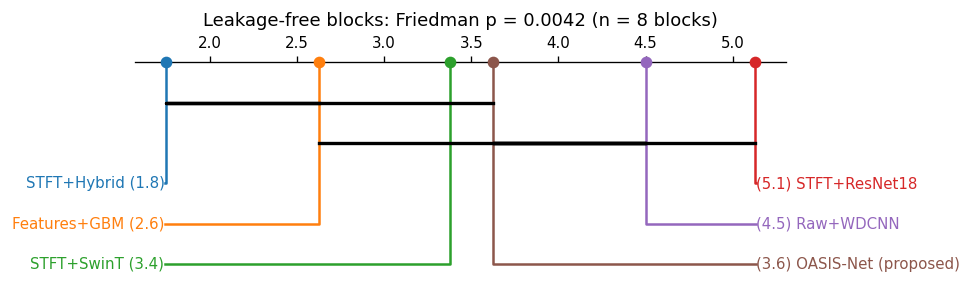

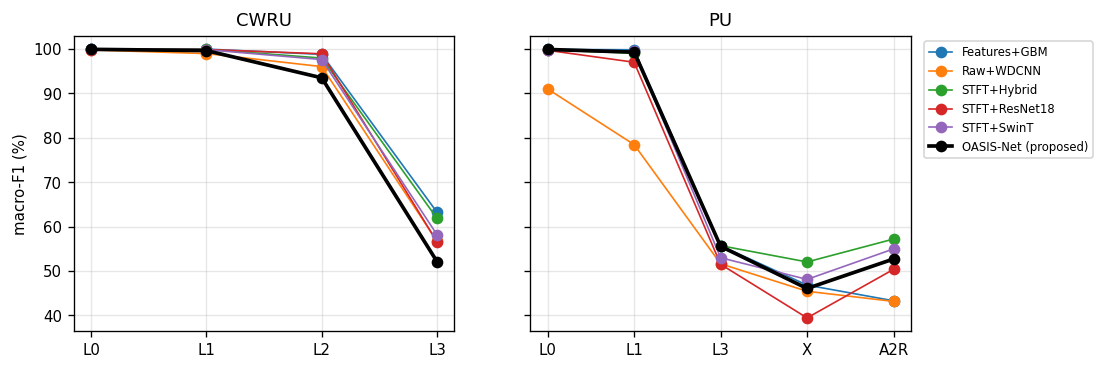

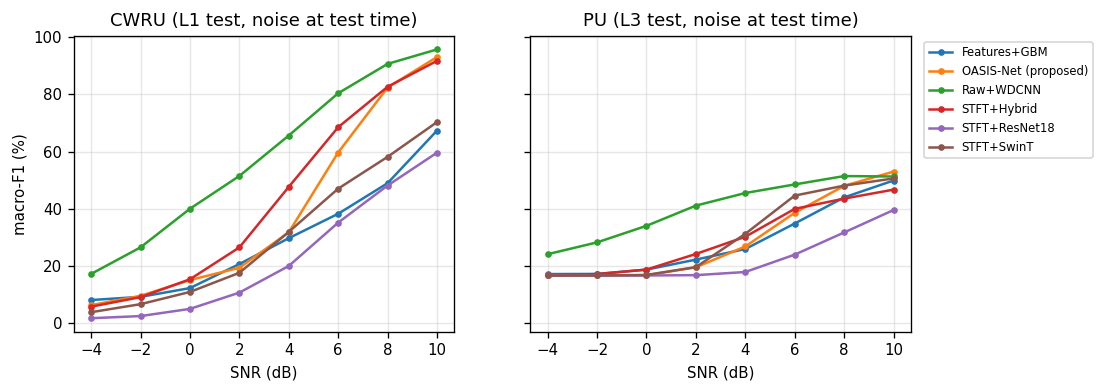

  cwru_non  STFT  4683 images in 1s
  cwru_non  GASF  4683 images in 1s
  cwru_non  GADF  4683 images in 1s
  cwru_non  MTF   4683 images in 1s
  cwru_non  RP    4683 images in 1s


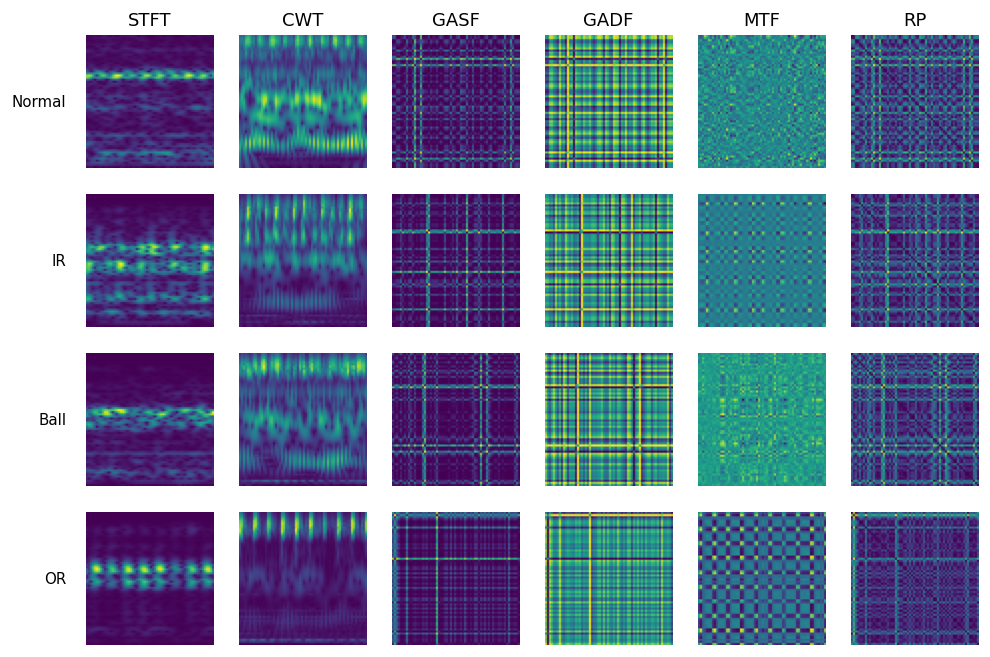

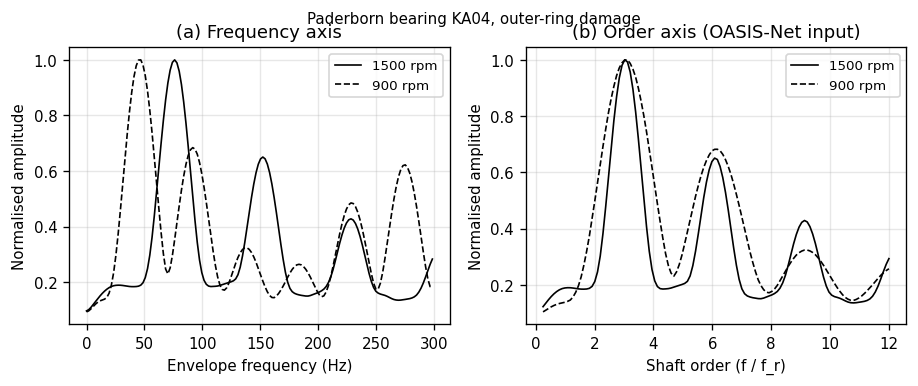

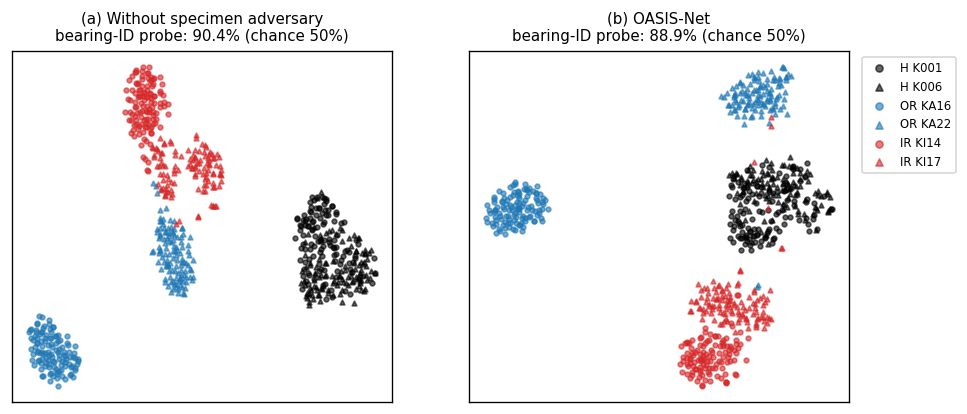

                             n_params  train_time_s  infer_ms_per_window  input_ms_per_window
config                                                                                       
Features+GBM                      NaN        19.941                0.026                  NaN
OASIS v1 w/o adversary     28369540.0       142.595                2.295                2.452
OASIS v1 w/o image branch     53770.0         2.623                0.031                0.127
OASIS v1 w/o order branch  28119172.0       123.502                2.296                2.325
OASIS w/o image branch        53770.0         2.008                0.011                0.127
OASIS w/o order branch     28119172.0       145.235                2.268                2.325
OASIS-Net (proposed)       28369540.0       142.082                2.275                2.452
OASIS-Net v1 (a priori)    28369540.0       140.714                2.302                2.452
Raw+WDCNN                     47910.0         2.454         

In [ ]:
# ---------- 11. Analysis: tables, statistics, figures, paper numbers ----------
import matplotlib.pyplot as plt
import scikit_posthocs as sp
from scipy.stats import friedmanchisquare, wilcoxon
plt.rcParams.update({'font.size': 9, 'figure.dpi': 120, 'savefig.dpi': 300, 'savefig.bbox': 'tight'})
TAB, FIG = OUT / 'tables', OUT / 'figs'

R = pd.read_csv(RES_F)
SEL2 = json.load(open(OUT / 'oasis2_selected.json'))['selected'] if (OUT / 'oasis2_selected.json').exists() else None
V2 = SEL2 is not None and (pd.read_csv(RES_F).model == 'oasis2').any()
OASIS_NAMES = {'oasis': 'OASIS-Net v1 (a priori)', 'oasis_noadv': 'OASIS v1 w/o adversary',
               'oasis_noorder': 'OASIS v1 w/o order branch', 'oasis_noimg': 'OASIS v1 w/o image branch',
               'oasis2': 'OASIS-Net (proposed)', 'oasis2_noadv': 'OASIS w/o adversary',
               'oasis2_noorder': 'OASIS w/o order branch', 'oasis2_noimg': 'OASIS w/o image branch',
               'oasis2_nomix': 'OASIS w/o specimen mixing'}
if not V2:   # before cell 10c has run, the a-priori model is the proposed one
    OASIS_NAMES.update(oasis='OASIS-Net (proposed)', oasis_noadv='OASIS w/o adversary',
                       oasis_noorder='OASIS w/o order branch', oasis_noimg='OASIS w/o image branch')
R['config'] = np.where(R.model == 'gbm', 'Features+GBM', np.where(R.model == 'wdcnn', 'Raw+WDCNN',
              np.where(R.model.str.startswith('oasis'), R.model.map(OASIS_NAMES),
                       R['transform'] + '+' + R['model'].map({'resnet18': 'ResNet18', 'swin': 'SwinT', 'hybrid': 'Hybrid'}))))
clean = R[R.snr_db.isna()].copy()
clean['col'] = clean.dataset + ' ' + np.where(clean.test.str.startswith('X-'), 'X', clean.protocol.replace({'L3X': 'L3'}))
COLS = ['CWRU L0', 'CWRU L1', 'CWRU L2', 'CWRU L3', 'PU L0', 'PU L1', 'PU L3', 'PU X', 'PU A2R']
LEAKFREE = ['CWRU L3', 'PU L3', 'PU X', 'PU A2R']

def save_table(df, name, fmt='{:.1f}'):
    df.to_csv(TAB / f'{name}.csv')
    (TAB / f'{name}.md').write_text(df.to_markdown())
    (TAB / f'{name}.tex').write_text(df.to_latex(escape=True))

# full-stage configs (3 seeds) for the main table; screening configs reported separately
full_cfg = clean.groupby('config').seed.nunique()
full_cfg = list(full_cfg[full_cfg >= len(CFG['SEEDS'])].index)
# per seed: average over folds/test-sets inside a column, then mean ± sd over seeds
per_seed = clean.groupby(['config', 'col', 'seed']).macro_f1.mean().reset_index()
agg = per_seed.groupby(['config', 'col']).macro_f1.agg(['mean', 'std']).reset_index()
pivot_m = agg.pivot(index='config', columns='col', values='mean').reindex(columns=COLS) * 100
pivot_s = agg.pivot(index='config', columns='col', values='std').reindex(columns=COLS) * 100
main = pivot_m.loc[[c for c in pivot_m.index if c in full_cfg]]
PROPOSED = 'OASIS-Net (proposed)'
ABLATIONS = ([OASIS_NAMES[k] for k in ('oasis2_noadv', 'oasis2_noorder', 'oasis2_noimg', 'oasis2_nomix')] +
             [OASIS_NAMES['oasis']] if V2 else [OASIS_NAMES[k] for k in ('oasis_noadv', 'oasis_noorder', 'oasis_noimg')])
base_cfg = [c for c in main.index if not c.startswith('OASIS')]          # existing pipelines (benchmark)
cmp_cfg = base_cfg + ([PROPOSED] if PROPOSED in main.index else [])       # proposed vs existing (no ablations)
main_fmt = (main.round(1).astype(str) + ' ± ' + pivot_s.loc[main.index].round(1).fillna(0).astype(str)).loc[cmp_cfg]
save_table(main_fmt, 'table_main_macroF1')
screen = clean[(clean.model == 'resnet18') & clean.seed.isin(CFG['SCREEN_SEEDS'])]
screen_t = (screen.groupby(['transform', 'col']).macro_f1.mean().unstack().reindex(columns=COLS) * 100).round(1)
screen_t['val_macroF1'] = (screen.drop_duplicates('run_key').groupby('transform').val_macro_f1.mean() * 100).round(1)
save_table(screen_t, 'table_screening_resnet18')
print('MAIN (macro-F1 %, mean ± sd over seeds)\n', main_fmt.to_string())
print('\nSCREENING (ResNet-18, seed 0)\n', screen_t.to_string())

# CWRU L3 with the healthy class removed from the average (CWRU has a single healthy bearing, see paper Sec. 3.3)
l3 = clean[(clean.dataset == 'CWRU') & (clean.protocol == 'L3')].copy()
l3['fault_macro_f1'] = l3.f1_per_class.map(lambda s: float(np.mean(json.loads(s)[1:])))
fo = l3.groupby(['config', 'seed']).fault_macro_f1.mean().groupby('config').agg(['mean', 'std']) * 100
fo = fo.loc[[c for c in fo.index if c in full_cfg]]
save_table((fo['mean'].round(1).astype(str) + ' ± ' + fo['std'].round(1).fillna(0).astype(str)).to_frame('CWRU L3 fault-only macro-F1 (%)'),
           'table_cwru_l3_faultonly')

# inflation: L0 minus the strictest protocol of each dataset
infl = pd.DataFrame({'CWRU L0-L3': pivot_m['CWRU L0'] - pivot_m['CWRU L3'],
                     'PU L0-L3': pivot_m['PU L0'] - pivot_m['PU L3'],
                     'PU L0-A2R': pivot_m['PU L0'] - pivot_m['PU A2R']}).round(1)
save_table(infl, 'table_inflation')

# ablation of OASIS-Net (leakage-free columns + mean); delta = variant minus full model
abl_rows = [c for c in [PROPOSED] + ABLATIONS if c in main.index]
abl = main.loc[abl_rows, ['CWRU L0', 'PU L0'] + LEAKFREE].copy()
abl['Leakage-free mean'] = abl[LEAKFREE].mean(1)
if PROPOSED in abl.index:
    abl['Δ vs full (leakage-free)'] = abl['Leakage-free mean'] - abl.loc[PROPOSED, 'Leakage-free mean']
save_table(abl.round(1), 'table_ablation')
print('ABLATION\n', abl.round(1).to_string())

# Friedman + Nemenyi on leakage-free blocks (each block = one fold/test-set, mean over seeds)
lf = clean[clean.config.isin(cmp_cfg) & clean.col.isin(LEAKFREE)]
blocks = lf.groupby(['config', 'fold', 'test']).macro_f1.mean().unstack('config').dropna()
fried = friedmanchisquare(*[blocks[c].values for c in blocks.columns]) if blocks.shape[1] > 2 and len(blocks) > 1 else None
ranks = blocks.rank(axis=1, ascending=False).mean().sort_values()
save_table(ranks.to_frame('mean_rank'), 'table_mean_rank_leakfree', fmt='{:.2f}')
if fried is not None:
    nem = sp.posthoc_nemenyi_friedman(blocks.values)
    nem.index = nem.columns = blocks.columns
    nem.to_csv(TAB / 'nemenyi_p.csv')
    fig, ax = plt.subplots(figsize=(7, 2.4))
    sp.critical_difference_diagram(ranks, nem, ax=ax)
    ax.set_title(f'Leakage-free blocks: Friedman p = {fried.pvalue:.2g} (n = {len(blocks)} blocks)')
    fig.savefig(FIG / 'fig_cd_diagram.png'); fig.savefig(FIG / 'fig_cd_diagram.pdf'); plt.show()

# figure: the leakage ladder
fig, axes = plt.subplots(1, 2, figsize=(9, 3.2), sharey=True)
for ax, ds, cols in zip(axes, ['CWRU', 'PU'], [COLS[:4], COLS[4:]]):
    for c in cmp_cfg:
        ax.plot(range(len(cols)), main.loc[c, cols].values, marker='o', lw=2.2 if c == PROPOSED else 1.0,
                color='black' if c == PROPOSED else None, label=c)
    ax.set_xticks(range(len(cols))); ax.set_xticklabels([c.split(' ')[1] for c in cols]); ax.set_title(ds); ax.grid(alpha=.3)
axes[0].set_ylabel('macro-F1 (%)'); axes[1].legend(fontsize=7, bbox_to_anchor=(1.02, 1), loc='upper left')
fig.savefig(FIG / 'fig_leakage_ladder.png'); fig.savefig(FIG / 'fig_leakage_ladder.pdf'); plt.show()

# figure: noise robustness
noisy = R[R.snr_db.notna() & R.config.isin(cmp_cfg)]
fig, axes = plt.subplots(1, 2, figsize=(9, 3.2), sharey=True)
for ax, ds in zip(axes, ['CWRU', 'PU']):
    d = noisy[noisy.dataset == ds].groupby(['config', 'snr_db']).macro_f1.mean().unstack(0) * 100
    for c in d.columns:
        ax.plot(d.index, d[c], marker='.', label=c)
    p, t = CFG['NOISE_TESTS'][ds]
    ax.set_title(f'{ds} ({p.replace("L3X", "L3")} test, noise at test time)'); ax.set_xlabel('SNR (dB)'); ax.grid(alpha=.3)
axes[0].set_ylabel('macro-F1 (%)'); axes[1].legend(fontsize=7, bbox_to_anchor=(1.02, 1), loc='upper left')
fig.savefig(FIG / 'fig_noise.png'); fig.savefig(FIG / 'fig_noise.pdf'); plt.show()
noise_t = (noisy.groupby(['dataset', 'config', 'snr_db']).macro_f1.mean().unstack('snr_db') * 100).round(1)
save_table(noise_t, 'table_noise')

# figure: example images (CWRU, 0 hp, one window per class for 4 classes)
_, Mn = POOLS['cwru_non']
pick = [Mn.index[(Mn.cls == c) & (Mn.cond == '0hp')][3] for c in ['N', 'IR007', 'B007', 'OR007']]
fig, axes = plt.subplots(4, len(CFG['TRANSFORMS']), figsize=(1.6 * len(CFG['TRANSFORMS']), 6.6))
for j, tf in enumerate(CFG['TRANSFORMS']):
    I = get_images('cwru_non', tf)
    for i, k in enumerate(pick):
        axes[i, j].imshow(I[k].astype(np.float32), cmap='viridis', aspect='auto'); axes[i, j].axis('off')
        if i == 0: axes[i, j].set_title(tf)
        if j == 0: axes[i, j].text(-0.15, .5, ['Normal', 'IR', 'Ball', 'OR'][i], transform=axes[i, j].transAxes, ha='right', va='center')
fig.savefig(FIG / 'fig_transform_examples.png'); fig.savefig(FIG / 'fig_transform_examples.pdf'); plt.show()

# figure: order normalisation -- one real OR-damage bearing at 1500 and 900 rpm, envelope spectrum vs order spectrum
def envelope_spectrum(X, fs):
    nfft, win = 8 * X.shape[1], np.hanning(X.shape[1])
    env = np.abs(ss.hilbert(_z(X), axis=1)); env -= env.mean(1, keepdims=True)
    return np.fft.rfftfreq(nfft, 1.0 / fs), np.abs(np.fft.rfft(env * win, n=nfft, axis=1)).mean(0)
Xp, Mp = POOLS['pu_non']
ORDER_BEARING = next((b for b in PU_REAL['OR'] + PU_ART['OR']
                      if all(((Mp.bearing == b) & (Mp.cond == c)).any() for c in ('N15_M07_F10', 'N09_M07_F10'))), None)
if ORDER_BEARING:
    fig, axes = plt.subplots(1, 2, figsize=(9, 3.0))
    for cond, ls in (('N15_M07_F10', '-'), ('N09_M07_F10', '--')):
        idx = np.where(((Mp.bearing == ORDER_BEARING) & (Mp.cond == cond)).values)[0]
        fs, rpm = Mp.fs.values[idx[0]], Mp.rpm.values[idx[0]]
        f, E = envelope_spectrum(Xp[idx], fs)
        keep = f <= 12 * 1500 / 60
        axes[0].plot(f[keep], E[keep] / E[keep][f[keep] > 2].max(), ls, color='black', lw=1, label=f'{int(rpm)} rpm')
        o = np.interp(ORD_GRID * rpm / 60, f, E)
        axes[1].plot(ORD_GRID, o / o[ORD_GRID > 0.5].max(), ls, color='black', lw=1, label=f'{int(rpm)} rpm')
    axes[0].set_xlabel('Envelope frequency (Hz)'); axes[1].set_xlabel('Shaft order (f / f_r)')
    for ax, t in zip(axes, ('(a) Frequency axis', '(b) Order axis (OASIS-Net input)')):
        ax.set_ylabel('Normalised amplitude'); ax.set_title(t); ax.legend(fontsize=8); ax.grid(alpha=.3)
    fig.suptitle(f'Paderborn bearing {ORDER_BEARING}, outer-ring damage', fontsize=9)
    fig.savefig(FIG / 'fig_order_normalisation.png'); fig.savefig(FIG / 'fig_order_normalisation.pdf'); plt.show()

# figure: specimen invariance -- t-SNE of fused features (PU L3 test bearings) + within-class bearing-ID probe
from sklearn.manifold import TSNE
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
def probe_acc(f, yv, b):
    """5-fold CV accuracy of identifying the bearing within each class (chance = 1 / bearings per class)."""
    accs, chance = [], []
    for c in np.unique(yv):
        m = yv == c
        codes = pd.factorize(b[m])[0]
        if codes.max() < 1:
            continue
        k = int(min(5, np.bincount(codes).min()))
        if k < 2:
            continue
        clf = make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000))
        accs.append(cross_val_score(clf, f[m], codes, cv=StratifiedKFold(k, shuffle=True, random_state=0)).mean())
        chance.append(1 / (codes.max() + 1))
    return (float(np.mean(accs)) if accs else np.nan), (float(np.mean(chance)) if chance else np.nan)
EMB_KEYS = ('oasis2', 'oasis2_noadv') if V2 and (OUT / 'embeddings' / 'oasis2_noadv.npz').exists() else ('oasis', 'oasis_noadv')
EMB = {k: np.load(OUT / 'embeddings' / f'{k}.npz', allow_pickle=True) for k in EMB_KEYS
       if (OUT / 'embeddings' / f'{k}.npz').exists()}
EMB = {('oasis' if k.startswith('oasis2') and not k.endswith('noadv') else 'oasis' if k == 'oasis' else 'oasis_noadv'): v
       for k, v in EMB.items()}
PROBE = {}
if len(EMB) == 2:
    fig, axes = plt.subplots(1, 2, figsize=(9, 3.8))
    marks = ['o', '^', 's', 'D']
    for ax, (k, ttl) in zip(axes, (('oasis_noadv', '(a) Without specimen adversary'), ('oasis', '(b) OASIS-Net'))):
        e = EMB[k]; f, yv, b = e['f'], e['y'], e['bearing'].astype(str)
        PROBE[k] = probe_acc(f, yv, b)
        z = TSNE(2, perplexity=min(30, max(5, len(f) // 10)), init='pca', random_state=0).fit_transform(StandardScaler().fit_transform(f))
        for ci, c in enumerate(np.unique(yv)):
            for bi, bb in enumerate(sorted(set(b[yv == c]))):
                m = (yv == c) & (b == bb)
                ax.scatter(z[m, 0], z[m, 1], s=8, marker=marks[bi % 4], color=['black', 'tab:blue', 'tab:red'][ci % 3],
                           alpha=.6, label=f'{PU_CLASSES[c]} {bb}')
        ax.set_title(f'{ttl}\nbearing-ID probe: {100 * PROBE[k][0]:.1f}% (chance {100 * PROBE[k][1]:.0f}%)', fontsize=9)
        ax.set_xticks([]); ax.set_yticks([])
    axes[1].legend(fontsize=7, markerscale=1.5, bbox_to_anchor=(1.02, 1), loc='upper left')
    fig.savefig(FIG / 'fig_specimen_invariance.png'); fig.savefig(FIG / 'fig_specimen_invariance.pdf'); plt.show()
else:
    print('embeddings for PU|L3X seed 0 not found: delete the two OASIS rows of that fold from results.csv and re-run to create them')

# cost table
cost = clean[clean.config.isin(full_cfg)].groupby('config').agg(n_params=('n_params', 'first'),
       train_time_s=('train_time_s', 'mean'), infer_ms_per_window=('infer_ms', 'mean')).round(3)
_ct = COST.set_index('transform').ms_per_window
def _input_cost(c):
    if c.startswith('OASIS'):
        enc = 'CWT' if ('v1' in c or not V2) else SEL2['enc']
        return (0 if 'image branch' in c else _ct[enc]) + (0 if 'order branch' in c else _ct['order'])
    if c == 'Features+GBM' or c == 'Raw+WDCNN':
        return np.nan
    return _ct.get(c.split('+')[0], np.nan)
cost['input_ms_per_window'] = cost.index.map(_input_cost).astype(float).round(3)
save_table(cost, 'table_cost')
print(cost.to_string())

# ---- numbers for the manuscript placeholders ----
img_cfg = [c for c in base_cfg if not c.startswith(('Raw', 'Features'))]
bm = main.loc[base_cfg]
best_lf = ranks.index[0] if len(ranks) else None
N = {
    'N_WINDOWS_CWRU_OVL': len(POOLS['cwru_ovl'][0]), 'N_WINDOWS_CWRU_NON': len(POOLS['cwru_non'][0]),
    'N_WINDOWS_PU_OVL': len(POOLS['pu_ovl'][0]), 'N_WINDOWS_PU_NON': len(POOLS['pu_non'][0]),
    'OVERLAP_FRAC_CWRU_L0': round(100 * AUDIT[AUDIT.fold == 'CWRU|L0'].overlap_frac.iloc[0], 1),
    'OVERLAP_FRAC_PU_L0': round(100 * AUDIT[AUDIT.fold == 'PU|L0'].overlap_frac.iloc[0], 1),
    'SELECTED_TRANSFORMS': ', '.join(TOP),
    'CWRU_L0_RANGE': f"{bm['CWRU L0'].min():.1f}–{bm['CWRU L0'].max():.1f}",
    'CWRU_L3_RANGE': f"{bm['CWRU L3'].min():.1f}–{bm['CWRU L3'].max():.1f}",
    'PU_L0_RANGE': f"{bm['PU L0'].min():.1f}–{bm['PU L0'].max():.1f}",
    'PU_L3_RANGE': f"{bm['PU L3'].min():.1f}–{bm['PU L3'].max():.1f}",
    'PU_X_RANGE': f"{bm['PU X'].min():.1f}–{bm['PU X'].max():.1f}",
    'PU_A2R_RANGE': f"{bm['PU A2R'].min():.1f}–{bm['PU A2R'].max():.1f}",
    'MEAN_INFLATION_CWRU_IMG': round(infl.loc[img_cfg, 'CWRU L0-L3'].mean(), 1),
    'MEAN_INFLATION_PU_IMG': round(infl.loc[img_cfg, 'PU L0-L3'].mean(), 1),
    'MAX_INFLATION_CWRU': f"{infl.loc[base_cfg, 'CWRU L0-L3'].max():.1f} ({infl.loc[base_cfg, 'CWRU L0-L3'].idxmax()})",
    'MAX_INFLATION_PU': f"{infl.loc[base_cfg, 'PU L0-L3'].max():.1f} ({infl.loc[base_cfg, 'PU L0-L3'].idxmax()})",
    'BEST_LEAKFREE_CONFIG': best_lf, 'BEST_LEAKFREE_RANK': round(ranks.iloc[0], 2) if len(ranks) else None,
    'RANK_GBM': round(ranks.get('Features+GBM', np.nan), 2), 'RANK_WDCNN': round(ranks.get('Raw+WDCNN', np.nan), 2),
    'FRIEDMAN_CHI2': round(fried.statistic, 2) if fried else None, 'FRIEDMAN_P': f'{fried.pvalue:.2g}' if fried else None,
    'N_BLOCKS': len(blocks), 'N_CONFIGS_FULL': len(full_cfg), 'N_BASELINES': len(base_cfg), 'PU_N_MEAS': CFG['PU_N_MEAS'], 'N_TOPK': CFG['TOPK'],
    'CWRU_L3_FAULTONLY_RANGE': f"{fo['mean'].min():.1f}–{fo['mean'].max():.1f}" if len(fo) else None,
}
# proposed model: per-column scores, gain over the best existing pipeline, paired Wilcoxon, ablation deltas
if PROPOSED in main.index:
    for col in COLS:
        N['OASIS_' + col.replace(' ', '_')] = round(main.loc[PROPOSED, col], 1)
    lf_mean = main.loc[cmp_cfg, LEAKFREE].mean(1)
    best_base = lf_mean.loc[base_cfg].idxmax()
    N.update(OASIS_LF_MEAN=round(lf_mean[PROPOSED], 1), BEST_BASELINE=best_base,
             BEST_BASELINE_LF_MEAN=round(lf_mean[best_base], 1), OASIS_LF_GAIN=round(lf_mean[PROPOSED] - lf_mean[best_base], 1),
             OASIS_RANK=round(ranks.get(PROPOSED, np.nan), 2),
             OASIS_INFL_CWRU=round(infl.loc[PROPOSED, 'CWRU L0-L3'], 1), OASIS_INFL_PU=round(infl.loc[PROPOSED, 'PU L0-L3'], 1))
    if best_base in blocks.columns and PROPOSED in blocks.columns and len(blocks) >= 6:
        w = wilcoxon(blocks[PROPOSED], blocks[best_base])
        N.update(WILCOXON_PAIR=f'{PROPOSED} vs {best_base}', WILCOXON_P=f'{w.pvalue:.2g}',
                 WILCOXON_MEAN_DIFF=round(100 * (blocks[PROPOSED] - blocks[best_base]).mean(), 1))
    for k, nm in zip(('ABL_NOADV', 'ABL_NOORDER', 'ABL_NOIMG', 'ABL_NOMIX', 'ABL_V1'), ABLATIONS):
        if nm in abl.index:
            N[k + '_DELTA'] = round(abl.loc[nm, 'Δ vs full (leakage-free)'], 1)
for ds in ['CWRU', 'PU']:
    d = noisy[noisy.dataset == ds].groupby(['config', 'snr_db']).macro_f1.mean().unstack(0) * 100
    if len(d) and 0 in d.index:
        N[f'NOISE_0DB_BEST_{ds}'] = f"{d.loc[0].max():.1f} ({d.loc[0].idxmax()})"
        N[f'NOISE_0DB_WORST_{ds}'] = f"{d.loc[0].min():.1f} ({d.loc[0].idxmin()})"
N['ORDER_FIG_BEARING'] = ORDER_BEARING
if SEL2:
    N.update(SEL_ENC=SEL2['enc'], SEL_IMG=SEL2['img'], SEL_LAM=SEL2['lam'], SEL_MIX=SEL2['mix'],
             SEL_INNER_F1=round(100 * SEL2['inner_f1'], 1))
N['EPOCHS'] = CFG['EPOCHS']
if PROBE:
    N.update(PROBE_ACC_OASIS=round(100 * PROBE['oasis'][0], 1), PROBE_ACC_NOADV=round(100 * PROBE['oasis_noadv'][0], 1),
             PROBE_CHANCE=round(100 * PROBE['oasis'][1], 1))
json.dump(N, open(OUT / 'paper_numbers.json', 'w'), indent=1, default=str)
(OUT / 'paper_numbers.md').write_text('\n'.join(f'- {{{{{k}}}}} = {v}' for k, v in N.items()))
print('\n'.join(f'{k:28s} {v}' for k, v in N.items()))
print('\nAll tables in', TAB, '\nAll figures in', FIG)